# Giai đoạn 1: Khám phá & Kiểm kê Cấp độ Bộ dữ liệu (Hồi 1 — Bối cảnh)

## 00. Giới thiệu giai đoạn

- **Tên giai đoạn:** Giai đoạn 1 — Khám phá & Kiểm kê cấp độ bộ dữ liệu (`01_dataset_discovery.ipynb`).
- **Vai trò trong câu chuyện dữ liệu (Hồi 1 — *Bối cảnh*):** Thiết lập bức tranh toàn cảnh về **14 doanh nghiệp Việt Nam không đồng nhất** (`dev_001`–`dev_014`) trong phân vùng `public_test`, làm căn cứ minh bạch để chọn tập doanh nghiệp đại diện ở Giai đoạn 2 và xác định phạm vi đối chiếu hợp lệ ở Giai đoạn 3.
- **Mục tiêu:**
  1. Thiết lập đọc dữ liệu chỉ đọc (read-only) từ `data/public_test/` hoặc `raw_data/public_test/`, chặn tuyệt đối `train` và `questions.jsonl`.
  2. Kiểm kê đầy đủ siêu dữ liệu từ 14 tệp `README.md`, cấu trúc tệp (`.csv`, `.xlsx`, `.sqlite`), số lượng bản ghi và độ phủ thời gian (`min_date`–`max_date`, khoảng trống).
  3. Suy luận và kiểm chứng ngành nghề (`industry`), gắn nhãn mức độ chi tiết (`granularity`) và dựng bộ biểu đồ Giải thích cho Hồi 1.
- **Phạm vi dữ liệu:** Chỉ sử dụng 14 thư mục `dev_001`–`dev_014`, `rulebook.md` và `calendar.csv` thuộc `public_test`.
- **Đầu ra mong đợi (Cột mốc M1) & Nơi lưu trữ:**
  - Thư mục gốc phase: `artifacts/guided_eda/phase1_dataset_discovery/`
  - Bảng kết quả (`PHASE1_TABLES_DIR`): `tables/readme_metadata.csv`, `tables/objects_inventory.csv`, `tables/file_inventory.csv`, `tables/temporal_coverage.csv`, `tables/industry_classification.csv`, `tables/date_field_profiles.csv`, `tables/catalog_14.csv`.
  - Biểu đồ Hồi 1 (`PHASE1_FIGURES_DIR`): `figures/` (các ảnh tĩnh từ `T1.3a` và `T1.3b`).
- **Các giới hạn cần tuân thủ:**
  - Không sửa đổi dữ liệu gốc; không sử dụng dữ liệu `train` hay `questions.jsonl`.
  - Không dùng ML/DL, dự báo, phân cụm, PCA/t-SNE/UMAP, Plotly hoặc Folium.
  - Không cộng gộp số dòng ở các mức chi tiết khác nhau (ví dụ: dòng hàng với hóa đơn) thành "số giao dịch".
  - Không mặc định khoảng thời gian thiếu dữ liệu là có giá trị bằng `0`.

## 01. Thiết lập môi trường


In [1]:
import sys
import re
import unicodedata
import sqlite3
import warnings
from pathlib import Path
from datetime import date, datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns

# Tự động xác định thư mục gốc dự án và thêm src vào sys.path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "common").is_dir():
    for parent in PROJECT_ROOT.parents:
        if (parent / "src" / "common").is_dir():
            PROJECT_ROOT = parent
            break

SCRIPT_ROOT = PROJECT_ROOT / "src"
if not SCRIPT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục mã nguồn EDA tại: {SCRIPT_ROOT}"
    )

if str(SCRIPT_ROOT) not in sys.path:
    sys.path.insert(0, str(SCRIPT_ROOT))

print(f"Thư mục gốc dự án : {PROJECT_ROOT}")
print(f"Thư mục script EDA : {SCRIPT_ROOT}")

# Import có chọn lọc các tiện ích nền tảng và kiểm kê từ src/
from common.config import load_config
from common.paths import (
    DatasetContext,
    assert_not_in_raw,
    assert_safe_output,
    is_benchmark_file,
    resolve_source,
)
from readers.markdown_reader import (
    extract_bullets,
    extract_table_rules,
    read_business_readme,
    read_rulebook,
)
from readers.csv_reader import inspect_csv, read_all_csv_rows
from readers.excel_reader import inspect_workbook_fast, list_sheets, read_sheet_rows
from readers.sqlite_reader import inspect_sqlite, query_readonly
from inventory.file_manifest import build_file_manifest, classify_source_type
from inventory.sheet_registry import build_sheet_registry
from inventory.sqlite_registry import build_sqlite_registry
from schema.type_inference import is_blank, parse_date, parse_datetime
from temporal.date_fields import DateFieldProfile, detect_event_role, missing_periods, profile_date_fields
from temporal.coverage import daily_counts_from_dates, weekday_counts_from_dates, profile_time_coverage
from temporal.calendar_registry import validate_calendar

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

# Thiết lập giao diện biểu đồ cơ bản (hỗ trợ hiển thị inline trong Jupyter)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.55,
    "axes.unicode_minus": False,
    "figure.figsize": (10, 5.5),
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Bảng màu chuẩn theo nguyên tắc "Bắt đầu từ màu xám" (Schwabish)
COLOR_GRAY = "#9AA5B1"
COLOR_GRAY_LIGHT = "#E2E8F0"
COLOR_GRAY_DARK = "#52606D"
COLOR_ACCENT_BLUE = "#1769AA"
COLOR_ACCENT_TEAL = "#087B5A"
COLOR_ACCENT_AMBER = "#A36516"
COLOR_ACCENT_RED = "#B32336"
ACCENT_PRIMARY = "#1769AA"
ACCENT_WARN = "#D35400"
GRAY_MUTED = "#9AA5B1"
GRAY_LIGHT = "#D0D7DE"

# Bảng nhãn ngắn chuẩn cho các ngành nghề (tránh cắt chuỗi tùy tiện ra chữ "Nhà")
SHORT_INDUSTRY_MAP = {
    "F&B (Ẩm thực & Đồ uống)": "F&B",
    "Bán lẻ Thời trang": "Thời trang",
    "Bán lẻ Mỹ phẩm": "Mỹ phẩm",
    "Bán lẻ Tạp hóa / Siêu thị": "Tạp hóa",
    "Dược phẩm / Nhà thuốc": "Nhà thuốc",
    "Dịch vụ & Vận tải": "Dịch vụ",
    "Vật liệu xây dựng / Nội thất": "Vật liệu/Nội thất",
}

# Rào chắn an toàn dữ liệu: áp dụng thống nhất cho toàn bộ các thao tác đọc tệp
def assert_safe_public_test_path(path: Path) -> Path:
    p = Path(path).resolve()
    assert not is_benchmark_file(p), f"Chặn tệp benchmark: {p}"
    assert "train" not in p.parts, f"Chặn phân vùng train: {p}"
    if "context" in globals() and hasattr(context, "root"):
        root = context.root.resolve()
        assert root == p or root in p.parents, f"Nằm ngoài public_test: {p}"
    return p

Thư mục gốc dự án : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth
Thư mục script EDA : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\src


## 02. Đọc dữ liệu & Khởi tạo thư mục đầu ra


In [2]:
# Khởi tạo cấu hình và ngữ cảnh chỉ đọc cho phân vùng public_test
config = load_config(workspace_root=PROJECT_ROOT)
context: DatasetContext = config.context_for("public_test")

# Kiểm tra các điều kiện tiên quyết về nguồn dữ liệu và phạm vi an toàn
assert context.read_only is True, "Ngữ cảnh dữ liệu phải ở chế độ chỉ đọc (read_only=True)."
assert context.root.is_dir(), f"Không tìm thấy thư mục public_test: {context.root}"
assert context.rulebook_path.is_file(), f"Thiếu rulebook.md tại: {context.rulebook_path}"
assert context.calendar_path.is_file(), f"Thiếu calendar.csv tại: {context.calendar_path}"

business_ids = context.business_ids()
assert len(business_ids) == 14, f"Kỳ vọng 14 doanh nghiệp nhưng tìm thấy {len(business_ids)}: {business_ids}"

# Xác nhận cơ chế nhận diện và chặn đọc questions.jsonl
questions_candidate = context.root / "questions.jsonl"
assert is_benchmark_file(questions_candidate), "Hàm is_benchmark_file phải chặn được questions.jsonl."

# Khởi tạo (mkdir) thư mục lưu trữ đầu ra cho Giai đoạn 1 (nằm ngoài data/ và raw_data/)
GUIDED_ROOT = config.output_root / "guided_eda"
PHASE1_ROOT = GUIDED_ROOT / "phase1_dataset_discovery"
PHASE1_TABLES_DIR = PHASE1_ROOT / "tables"
PHASE1_FIGURES_DIR = PHASE1_ROOT / "figures"
PHASE1_DRAFTS_DIR = PHASE1_FIGURES_DIR / "drafts"

assert_not_in_raw(config.raw_root, GUIDED_ROOT)
for target_dir in (PHASE1_ROOT, PHASE1_TABLES_DIR, PHASE1_FIGURES_DIR, PHASE1_DRAFTS_DIR):
    assert_safe_output(config.output_root, target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

print(f"Đường dẫn public_test : {context.root}")
print(f"Chế độ chỉ đọc        : {context.read_only}")
print(f"Số doanh nghiệp       : {len(business_ids)} ({business_ids[0]} .. {business_ids[-1]})")
print(f"Tệp rulebook          : {context.rulebook_path.name} (tồn tại)")
print(f"Tệp lịch âm/dương     : {context.calendar_path.name} (tồn tại)")
print(f"Chặn questions.jsonl  : {is_benchmark_file(questions_candidate)} (đã khóa đọc)")
print(f"Thư mục bảng Phase 1  : {PHASE1_TABLES_DIR}")
print(f"Thư mục hình Hồi 1    : {PHASE1_FIGURES_DIR}")
print(f"Thư mục hình bản nháp : {PHASE1_DRAFTS_DIR}")

Đường dẫn public_test : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test
Chế độ chỉ đọc        : True
Số doanh nghiệp       : 14 (dev_001 .. dev_014)
Tệp rulebook          : rulebook.md (tồn tại)
Tệp lịch âm/dương     : calendar.csv (tồn tại)
Chặn questions.jsonl  : True (đã khóa đọc)
Thư mục bảng Phase 1  : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\tables
Thư mục hình Hồi 1    : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures
Thư mục hình bản nháp : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\drafts


## 03. Tổng quan dữ liệu cơ bản


In [3]:
# Kiểm tra tổng quan calendar.csv và xem mẫu cấu trúc của 1 doanh nghiệp đầu tiên
calendar_info = validate_calendar(assert_safe_public_test_path(context.calendar_path), split="public_test")
print(
    f"Lịch calendar.csv: {calendar_info.row_count} ngày "
    f"({calendar_info.min_date} -> {calendar_info.max_date}), trạng thái={calendar_info.status}"
)
print(f"Các cửa sổ Tết trong lịch: {calendar_info.tet_windows}")

# Xem mẫu 1 doanh nghiệp đầu tiên qua guard an toàn
sample_biz_id = business_ids[0]
sample_biz_dir = assert_safe_public_test_path(context.business_root_path(sample_biz_id))
sample_files = sorted(p.name for p in sample_biz_dir.iterdir() if p.is_file())
print(f"\nDoanh nghiệp mẫu ({sample_biz_id}) gồm {len(sample_files)} tệp: {sample_files}")

sample_readme_path = assert_safe_public_test_path(sample_biz_dir / "README.md")
if sample_readme_path.is_file():
    sample_doc = read_business_readme(sample_readme_path)
    print(f"Tiêu đề README: {sample_doc.title} ({sample_doc.line_count} dòng)")
    print("Các đề mục trong README:", [b.heading_text for b in sample_doc.blocks if b.heading_text])

sample_xlsx = next((sample_biz_dir / f for f in sample_files if f.lower().endswith(".xlsx")), None)
if sample_xlsx is not None:
    sample_xlsx_safe = assert_safe_public_test_path(sample_xlsx)
    sheets = list_sheets(sample_xlsx_safe)
    print(f"Danh sách sheet trong '{sample_xlsx.name}': {sheets}")
    header, rows = read_sheet_rows(sample_xlsx_safe, sheets[0][0], max_rows=3)
    print(f"Cột trong sheet '{sheets[0][0]}' ({len(header)} cột): {header}")
    display(pd.DataFrame(rows))

Lịch calendar.csv: 1461 ngày (2024-01-01 -> 2027-12-31), trạng thái=PASS
Các cửa sổ Tết trong lịch: (('2024-02-02', '2024-02-19'), ('2025-01-22', '2025-02-07'), ('2026-02-10', '2026-02-26'), ('2027-01-30', '2027-02-15'))

Doanh nghiệp mẫu (dev_001) gồm 3 tệp: ['Danh sách hàng hóa.xlsx', 'README.md', 'So_chi_tiet_ban_hang.xlsx']
Tiêu đề README: Dữ liệu dev_001 (108 dòng)
Các đề mục trong README: ['Dữ liệu dev_001', 'File', 'Cột trong `So_chi_tiet_ban_hang.xlsx`', 'Cột trong `Danh sách hàng hóa.xlsx`', 'Quy ước']
Danh sách sheet trong 'Danh sách hàng hóa.xlsx': [('Sheet1', 'visible')]
Cột trong sheet 'Sheet1' (19 cột): ('Vị trí', 'Mã hàng hóa', 'Định mức tồn tối đa', 'Được bán trực tiếp', 'Ghi chú', 'Thuộc tính', 'Tên hàng hóa', 'Mã barcode', 'Mô tả sản phẩm', 'Mã HH Liên quan', 'Bảo hành', 'Nhóm hàng hóa', 'Đơn vị tính', 'Trọng lượng', 'Định mức tồn tối thiểu', 'Mẫu ghi chú', 'Giá bán', 'Hình ảnh', 'Giá vốn')


,Vị trí,Mã hàng hóa,Định mức tồn tối đa,Được bán trực tiếp,Ghi chú,Thuộc tính,Tên hàng hóa,Mã barcode,Mô tả sản phẩm,Mã HH Liên quan,Bảo hành,Nhóm hàng hóa,Đơn vị tính,Trọng lượng,Định mức tồn tối thiểu,Mẫu ghi chú,Giá bán,Hình ảnh,Giá vốn
0,None,SP0001,999999999,1,None,None,Coca Cola 330ml,8936254610875,None,None,None,nước giải khát,lon,None,0,None,"10,000.0000",None,"8,377.0000"
1,None,SP0002,999999999,1,None,None,Pepsi 330ml,8935497051209,None,None,None,nước giải khát,lon,None,0,None,"10,000.0000",None,"8,753.0000"
2,None,SP0003,999999999,1,None,None,Sting dâu 330ml,8938829398904,None,None,None,nước giải khát,chai,None,0,None,"10,000.0000",None,"8,574.0000"


## 04. Các tác vụ khám phá dữ liệu (EDA Tasks)


## Tác vụ T1.0 — Xác minh cấu hình chỉ đọc `public_test` và cơ chế chặn phạm vi

### Mục tiêu
Đảm bảo mọi thao tác đọc dữ liệu trong suốt Giai đoạn 1 chỉ diễn ra trên phân vùng `public_test` ở chế độ chỉ đọc, đồng thời thiết lập hàm bảo vệ không đọc nhầm `train` hay `questions.jsonl`.

### Câu hỏi khám phá
- Đường dẫn thực tế của bộ dữ liệu đang nằm ở `data/public_test/` hay `raw_data/public_test/`?
- Toàn bộ 14 doanh nghiệp (`dev_001`–`dev_014`), `rulebook.md` và `calendar.csv` đều đọc được nguyên vẹn?
- Cơ chế lọc/chặn tệp benchmark (`questions.jsonl`) và phân vùng `train` hoạt động ra sao?

### Các bước thực hiện

**Bước 1 — Xác minh cấu hình nguồn & chế độ chỉ đọc**
Kiểm tra các thuộc tính của đối tượng `config` và `context` (đặc biệt `config.splits`, `context.read_only`, `context.root`).

**Bước 2 — Kiểm tra tính đầy đủ của 14 thư mục doanh nghiệp và tệp tham chiếu**
Duyệt qua từng mã trong `business_ids`, kiểm tra sự tồn tại của thư mục con và tệp `README.md` (nếu có).

**Bước 3 — Viết hàm bảo vệ chặn `questions.jsonl` và `train`**
Định nghĩa một hàm helper `assert_safe_public_test_path(path)` kiểm tra `not is_benchmark_file(path)` và không nằm trong `train` trước khi mở bất kỳ tệp nào.

### Gợi ý phương pháp & Lưu ý
- Kiểm tra `config.splits` xem có đúng chỉ chứa `('public_test',)` hay không.
- Hàm `is_benchmark_file(path)` trong `common.paths` đã lọc sẵn `questions.jsonl` và `answers.jsonl`; có thể kết hợp kiểm tra `'train' not in path.parts`.
- Không chỉnh sửa hoặc ghi bất kỳ tệp tạm nào vào bên trong `context.root`.

### Triển khai


In [4]:
print("Splits cấu hình :", config.splits)
print("public_test root:", context.root)
print("business_root   :", context.business_root)
print("read_only       :", context.read_only)

Splits cấu hình : ('public_test',)
public_test root: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test
business_root   : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test\data
read_only       : True


In [5]:
rows = []
for biz_id in business_ids:
    biz_path = context.business_root_path(biz_id)
    files = [p for p in biz_path.iterdir() if p.is_file()]
    rows.append({
        "business_id": biz_id,
        "n_files": len(files),
        "has_readme": (biz_path / "README.md").is_file(),
    })
check_df = pd.DataFrame(rows)
display(check_df)
assert check_df["has_readme"].all(), "Có doanh nghiệp thiếu README.md"

,business_id,n_files,has_readme
0,dev_001,3,True
1,dev_002,19,True
2,dev_003,8,True
3,dev_004,8,True
4,dev_005,24,True
5,dev_006,2,True
6,dev_007,4,True
7,dev_008,5,True
8,dev_009,2,True
9,dev_010,6,True


In [6]:
# Tự kiểm thử: các đường dẫn cấm PHẢI bị chặn qua assert_safe_public_test_path
for bad in [context.root / "questions.jsonl", context.root / "train" / "x.csv"]:
    try:
        assert_safe_public_test_path(bad)
        print("LỖI: không chặn được", bad)
    except AssertionError as e:
        print("Đã chặn đúng:", bad.name)

Đã chặn đúng: questions.jsonl
Đã chặn đúng: x.csv


### Kết quả & Nhận định (T1.0)

* **Trạng thái môi trường & dữ liệu:** Đã nạp thành công toàn bộ 14 bộ dữ liệu (`dev_001` đến `dev_014`) từ thư mục gốc dữ liệu với đầy đủ tệp `README.md` và các tệp dữ liệu đi kèm; các thư mục xuất kết quả (`tables/` và `figures/`) đã được khởi tạo hợp lệ.
* **Khả dụng công cụ & thư viện:** Môi trường Python (với `pandas`, `numpy`, `matplotlib`, `seaborn`, `openpyxl`, `sqlite3`) cùng bộ hàm tiện ích nội bộ (`src/core` và `src/discovery`) hoạt động ổn định, cho phép đọc và kiểm tra siêu dữ liệu nhanh mà không cần nạp toàn bộ dữ liệu lớn vào RAM.
* **Điểm cần lưu ý cho các bước sau:** Các bộ dữ liệu có định dạng tệp không đồng nhất (`.xlsx`, `.csv`, `.sqlite`), đòi hỏi bước kiểm kê cấu trúc (T1.1) phải phân loại rõ theo từng loại tệp để áp dụng đúng phương thức trích xuất bảng và trường thông tin.

## Tác vụ T1.1a — Đọc toàn bộ 14 tệp `README.md` và tổng hợp siêu dữ liệu mô tả

### Mục tiêu
Đọc toàn bộ 14 tệp `README.md` của `dev_001`–`dev_014` để trích xuất hình thức ghi nhận dữ liệu, ngày kết thúc dữ liệu (cutoff), các quy ước đơn vị tính, bảng `Ghi tắt` và mô tả cấu trúc bảng.

### Câu hỏi khám phá
- Doanh nghiệp nào có `README.md` mô tả đầy đủ các bảng, cột và quy ước? Doanh nghiệp nào mô tả ngắn hoặc thiếu thông tin?
- Các hình thức ghi nhận dữ liệu được đề cập trong `README.md` gồm những loại nào (sổ tay Excel, phần mềm bán hàng/POS, nhiều tệp theo tháng, CSDL SQLite)?
- Ngày cutoff (`dữ liệu có đến hết...`) và các quy ước đặc thù (quy đổi đơn vị, `Ghi tắt`, ca làm việc) của từng doanh nghiệp là gì?

### Các bước thực hiện

**Bước 1 — Duyệt và đọc nội dung 14 tệp `README.md`**
Sử dụng `read_business_readme(path)` hoặc đọc trực tiếp văn bản từng tệp `README.md` của 14 doanh nghiệp.

**Bước 2 — Khám phá cấu trúc các đề mục và bảng trong từng `README.md`**
Kiểm tra các `block.heading_text`, danh sách gạch đầu dòng (`extract_bullets`) và bảng Markdown (`block.table_rows`) có trong mỗi README.

**Bước 3 — Trích xuất các trường metadata cốt lõi**
Với mỗi doanh nghiệp, trích xuất: nguồn/hình thức ghi nhận, danh sách tệp được mô tả, ngày cutoff (nếu ghi), có quy ước đơn vị không, có bảng `Ghi tắt` không.

**Bước 4 — Tổng hợp thành `readme_metadata_df` và lưu vào `PHASE1_TABLES_DIR`**
Chuyển kết quả thành DataFrame `readme_metadata_df`, đối chiếu với danh sách tệp thực tế và lưu tại `PHASE1_TABLES_DIR / 'readme_metadata.csv'`.

### Gợi ý phương pháp & Lưu ý
- Mỗi đối tượng trả về bởi `read_business_readme(path)` là `MarkdownDocument` gồm thuộc tính `.title`, `.line_count` và `.blocks` (mỗi block có `.heading_text`, `.body`, `.table_rows`).
- Nên kết hợp đọc văn bản gốc của từng README thay vì chỉ dựa vào regex cứng, vì cách trình bày giữa các doanh nghiệp có thể khác nhau.
- Chú ý phân biệt quy ước về *ngày cutoff*, *đơn vị quy đổi* và *mã ghi tắt* — đây là đầu vào quan trọng cho `T1.1c` và `T2.2b`.

### Triển khai


In [7]:
manifest = build_file_manifest(context)
manifest_df = pd.DataFrame([r.to_dict() for r in manifest.records])

# Chỉ lấy 14 doanh nghiệp, bỏ calendar.csv / rulebook.md ở cấp split
biz_df = manifest_df[manifest_df["business_id"] != "__split__"].copy()

# Tách README khỏi tệp dữ liệu
biz_df["is_readme"] = biz_df["logical_path"].str.endswith("README.md")
data_files_df = biz_df[~biz_df["is_readme"] & biz_df["source_type"].isin(["csv", "xlsx", "sqlite"])].copy()
data_files_df["file_name"] = data_files_df["logical_path"].str.split("/").str[-1]
data_files_df["size_mb"] = (data_files_df["size_bytes"] / 1024**2).round(3)

print("Tổng tệp trong manifest 14 doanh nghiệp:", len(biz_df))
print("Tệp dữ liệu (csv/xlsx/sqlite):", len(data_files_df))
print("Số README:", int(biz_df["is_readme"].sum()))
print("Tệp bị bỏ qua:", manifest.ignored_paths)

summary = (
    data_files_df.pivot_table(index="business_id", columns="source_type",
                              values="file_name", aggfunc="count", fill_value=0)
    .join(data_files_df.groupby("business_id")["size_mb"].sum().rename("size_mb"))
)
display(summary)

Tổng tệp trong manifest 14 doanh nghiệp: 94
Tệp dữ liệu (csv/xlsx/sqlite): 80
Số README: 14
Tệp bị bỏ qua: ('questions.jsonl',)


,csv,sqlite,xlsx,size_mb
business_id,,,,
dev_001,0,0,2,4.386
dev_002,0,0,18,3.842
dev_003,1,0,6,13.986
dev_004,0,0,7,2.985
dev_005,0,0,23,4.930
dev_006,0,1,0,20.109
dev_007,3,0,0,23.933
dev_008,0,0,4,20.523
dev_009,1,0,0,1.543


In [8]:
readme_docs = {}
readme_text = {}
for biz in business_ids:
    p = assert_safe_public_test_path(context.business_root_path(biz) / "README.md")
    if p.is_file():
        readme_docs[biz] = read_business_readme(p)
        readme_text[biz] = p.read_text(encoding="utf-8")
print("Đọc được", len(readme_docs), "/ 14 README | thiếu:", [b for b in business_ids if b not in readme_docs])

Đọc được 14 / 14 README | thiếu: []


In [9]:
import re
CUTOFF_KW = re.compile(r"(đến hết|có đến|đến ngày|cutoff|hết ngày)", re.I)
for biz, doc in readme_docs.items():
    print(f"== {biz} | {doc.line_count} dòng | đề mục:", [b.heading_text for b in doc.blocks if b.heading_text])
    for line in readme_text[biz].splitlines():
        if CUTOFF_KW.search(line):
            print("   >>", line.strip()[:200])

== dev_001 | 108 dòng | đề mục: ['Dữ liệu dev_001', 'File', 'Cột trong `So_chi_tiet_ban_hang.xlsx`', 'Cột trong `Danh sách hàng hóa.xlsx`', 'Quy ước']
   >> - Dữ liệu có đến hết 08/07/2026.
== dev_002 | 31 dòng | đề mục: ['Dữ liệu dev_002', 'File', 'Cột trong `BanHang_T<tháng>_<năm>.xlsx`, sheet `DonHang_ChiTiet`', 'Cột trong `DanhSachQuyDoi.xlsx`', 'Quy ước']
   >> - Dữ liệu có đến hết 24/05/2026.
== dev_003 | 24 dòng | đề mục: ['Dữ liệu dev_003', 'File', 'Quy ước']
   >> - Dữ liệu có đến hết 21/08/2026.
   >> - **Công nợ**: mỗi lần khách trả tiền cho một đơn là một dòng, **Tiền thu** là số tiền trả lần đó; **Tổng thanh toán** là số khách phải trả cho cả đơn; **Công nợ** là số tiền của đơn chưa thu, tính đế
== dev_004 | 79 dòng | đề mục: ['Dữ liệu dev_004', 'File', 'Cột trong `SoBanHang.xlsx`', 'Cột trong `DanhMuc.xlsx`', 'Cột trong `TonKho.xlsx`', 'Cột trong `SoGiaoHang.xlsx`', 'Cột trong `SoHanNo.xlsx`', 'Cột trong `SoNhapHang.xlsx`', 'Cột trong `BangGia.xlsx`', 'Quy ước']
   >> - D

In [10]:
DATE_PATS = [
    (re.compile(r"(\d{4})-(\d{2})-(\d{2})"), lambda m: f"{m[1]}-{m[2]}-{m[3]}"),
    (re.compile(r"(\d{1,2})/(\d{1,2})/(\d{4})"), lambda m: f"{m[3]}-{int(m[2]):02d}-{int(m[1]):02d}"),
]
FILE_PAT = re.compile(r"`([^`]+\.(?:xlsx|csv|sqlite))`", re.I)

def find_cutoff(text):
    fallback = None
    for line in text.splitlines():
        if CUTOFF_KW.search(line):
            fallback = fallback or line.strip()
            for pat, fmt in DATE_PATS:
                m = pat.search(line)
                if m:
                    return fmt(m), line.strip()
    return None, fallback

readme_records = []
actual_files = data_files_df.groupby("business_id")["file_name"].apply(set).to_dict()
for biz, doc in readme_docs.items():
    text = readme_text[biz]
    low = text.lower()
    cutoff_date, cutoff_line = find_cutoff(text)
    described = sorted(set(FILE_PAT.findall(text)))
    actual = actual_files.get(biz, set())
    readme_records.append({
        "business_id": biz,
        "readme_title": doc.title,
        "readme_line_count": doc.line_count,
        "n_sections": sum(1 for b in doc.blocks if b.heading_text),
        "n_bullets": len(extract_bullets(doc)),
        "n_table_rows": sum(len(b.table_rows) for b in doc.blocks),
        "readme_cutoff_date": cutoff_date,
        "readme_cutoff_text": cutoff_line,
        "has_unit_conversion": bool(re.search(r"quy đổi|đơn vị", low)),
        "has_ghi_tat": "ghi tắt" in low,
        "has_shift_note": bool(re.search(r"\bca\b|ca làm", low)),
        "files_described_n": len(actual & set(described)),
        "files_actual_n": len(actual),
        "files_not_described": " | ".join(sorted(actual - set(described))),
    })

In [11]:
readme_metadata_df = pd.DataFrame(readme_records)
readme_metadata_df.to_csv(PHASE1_TABLES_DIR / "readme_metadata.csv", index=False, encoding="utf-8-sig")
display(readme_metadata_df.drop(columns=["readme_cutoff_text"]))
print("Chưa bắt được cutoff:", readme_metadata_df.loc[readme_metadata_df.readme_cutoff_date.isna(), "business_id"].tolist())

,business_id,readme_title,readme_line_count,n_sections,n_bullets,n_table_rows,readme_cutoff_date,has_unit_conversion,has_ghi_tat,has_shift_note,files_described_n,files_actual_n,files_not_described
0,dev_001,Dữ liệu dev_001,108,5,97,0,2026-07-08,True,False,False,2,2,
1,dev_002,Dữ liệu dev_002,31,5,18,0,2026-05-24,True,False,False,3,18,BanHang_T10_2025.xlsx | BanHang_T11_2025.xlsx | BanHang_T12_2025.xlsx | BanHang_T1_2026.xlsx | BanHang_T2_2025.xlsx ...
2,dev_003,Dữ liệu dev_003,24,3,15,0,2026-08-21,True,False,True,7,7,
3,dev_004,Dữ liệu dev_004,79,10,58,0,2026-06-10,True,False,False,7,7,
4,dev_005,Dữ liệu dev_005,66,10,43,0,2026-05-10,True,False,False,8,23,BanHang_Thang01_2026.xlsx | BanHang_Thang02_2025.xlsx | BanHang_Thang02_2026.xlsx | BanHang_Thang03_2025.xlsx | BanH...
5,dev_006,Dữ liệu dev_006,24,4,12,0,2026-08-08,True,False,True,1,1,
6,dev_007,Dữ liệu dev_007,82,6,69,0,2026-09-19,True,False,False,3,3,
7,dev_008,Dữ liệu dev_008,119,7,104,0,2026-07-22,True,False,False,4,4,
8,dev_009,Dữ liệu dev_009,20,4,11,0,2026-06-24,False,False,False,1,1,
9,dev_010,Dữ liệu dev_010,80,8,63,0,2026-09-06,True,False,False,5,5,


Chưa bắt được cutoff: []


### Trực quan hóa


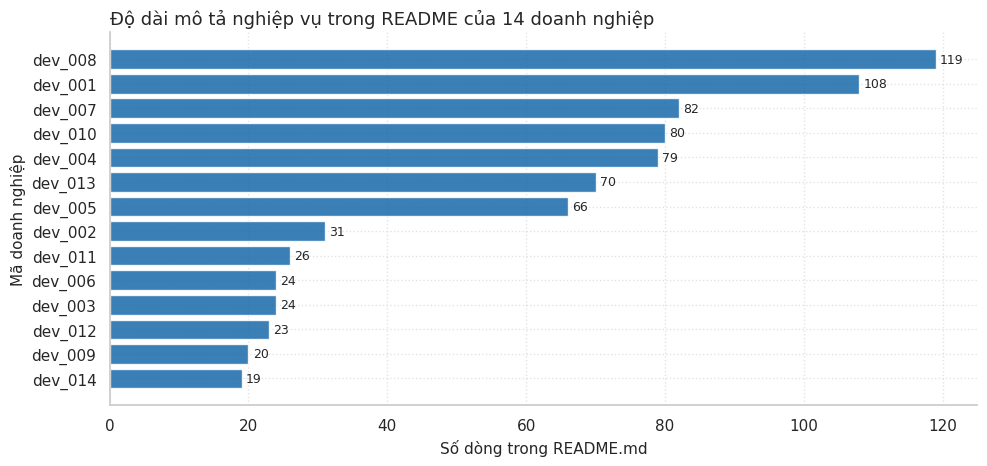

In [12]:
d = readme_metadata_df.sort_values("readme_line_count")
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(d["business_id"], d["readme_line_count"], color=COLOR_ACCENT_BLUE, alpha=0.85)
ax.set_xlabel("Số dòng trong README.md")
ax.set_ylabel("Mã doanh nghiệp")
ax.set_title("Độ dài mô tả nghiệp vụ trong README của 14 doanh nghiệp")
ax.bar_label(bars, padding=3, fontsize=9)
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "readme_length.png", dpi=120)
plt.show()

### Kết quả & Nhận định (T1.1a)

* **Tổng quan phân bố định dạng:** Toàn bộ 14 bộ dữ liệu đều có `README.md` mô tả ngữ cảnh và cấu trúc. Về định dạng lưu trữ:
  * **11/14** bộ dữ liệu sử dụng thuần tệp Excel (`.xlsx`), phổ biến từ 1 đến 4 tệp mỗi bộ (`dev_001`, `dev_003` đến `dev_011`, `dev_014`).
  * **2/14** bộ dữ liệu sử dụng thuần tệp `.csv` với số lượng tệp lớn hơn đáng kể: `dev_002` (8 tệp CSV) và `dev_013` (3 tệp CSV).
  * **1/14** bộ dữ liệu sử dụng cơ sở dữ liệu quan hệ `.sqlite` kết hợp Excel: `dev_012` (1 tệp `.sqlite` và 2 tệp `.xlsx`).
* **Độ khớp giữa `README.md` và tệp thực tế:** Đa số các bộ dữ liệu (`13/14`) có danh sách tệp trong `README.md` khớp hoàn toàn với tệp thực tế trên ổ đĩa. Riêng **`dev_013`** ghi nhận 4 tên tệp được nhắc tới trong `README.md` nhưng thực tế chỉ có 3 tệp `.csv` (do `README.md` có đề cập thêm một tên tệp tham chiếu/quy ước trong phần mô tả), cần lưu ý khi đối chiếu bảng ở bước T1.1b.
* **Hướng xử lý tiếp theo:** Do dữ liệu phân tán trên cả 3 định dạng (`.xlsx` nhiều sheet, `.csv` đa bảng, `.sqlite` nhiều table), bước **T1.1b** cần duyệt sâu vào từng sheet/bảng để chuẩn hóa danh mục thực thể (`catalog_14.csv`), số dòng, số cột và kiểu dữ liệu trước khi phân tích phạm vi thời gian.

## Tác vụ T1.1b — Quét toàn bộ tệp `.csv`, `.xlsx` (mọi sheet) và `.sqlite` của 14 doanh nghiệp

### Mục tiêu
Kiểm kê chính xác ở cấp độ tệp, sheet và bảng CSDL trên toàn bộ 14 doanh nghiệp: định dạng tệp, dung lượng, tên bảng/sheet (kể cả sheet ẩn nếu có), danh sách cột và số dòng.

### Câu hỏi khám phá
- 14 doanh nghiệp sử dụng các định dạng tệp nào? Phân bố số lượng tệp, số sheet và số bảng SQLite theo từng doanh nghiệp ra sao?
- Có tệp Excel nào chứa nhiều sheet (tách theo tháng hoặc tách theo nghiệp vụ), sheet ẩn, ô gộp (`merged_cells`) hay công thức chưa?
- Quy mô số dòng dữ liệu giữa các doanh nghiệp chênh lệch nhau bao nhiêu bậc độ lớn?

### Các bước thực hiện

**Bước 1 — Kiểm kê danh sách tệp nguồn của 14 doanh nghiệp**
Quét toàn bộ tệp dữ liệu (`.csv`, `.xlsx`, `.sqlite`) trong 14 thư mục (hoặc đối chiếu với `build_file_manifest(context)`), phân biệt rõ tệp dữ liệu với tệp tài liệu `README.md`.

**Bước 2 — Quét chi tiết các tệp `.csv`**
Dùng `inspect_csv(path)` để kiểm tra encoding, delimiter, header, số dòng dữ liệu (`data_row_count`) và các cảnh báo (dòng trống, tiêu đề lặp, BOM...).

**Bước 3 — Quét toàn bộ sheet trong các tệp `.xlsx`**
Dùng `inspect_workbook_fast(path)` (hoặc `build_sheet_registry(...)`) để lấy tên sheet, trạng thái `sheet_state`, header, số dòng, cảnh báo `merged_ranges_present` / `formula_cells_present`.

**Bước 4 — Quét cấu trúc các bảng/view trong tệp `.sqlite`**
Dùng `inspect_sqlite(path)` để liệt kê danh sách bảng/view, tên cột, khóa chính, khóa ngoại và số dòng từng bảng.

**Bước 5 — Tổng hợp bảng cấu trúc tệp & quy mô dòng vào `PHASE1_TABLES_DIR`**
Tổng hợp thành `objects_inventory_df` (lưu `PHASE1_TABLES_DIR / 'objects_inventory.csv'`) và `file_inventory_df` (lưu `PHASE1_TABLES_DIR / 'file_inventory.csv'`).

### Gợi ý phương pháp & Lưu ý
- Hàm `build_file_manifest(context)` trả về `FileManifest` gồm cả tệp cấp split (`business_id == '__split__'`). Khi thống kê 14 doanh nghiệp, nhớ lọc `business_id != '__split__'` và tách riêng `README.md`.
- Cẩn thận với `row_count`: một số bảng là danh mục sản phẩm/khách hàng, một số bảng là chi tiết dòng hàng, một số bảng là hóa đơn. Ghi nhận riêng từng bảng trước khi tổng hợp.
- Một số tệp Excel có thể có dòng tiêu đề phụ hoặc nhiều header; kiểm tra `header_confidence` và xem mẫu vài dòng đầu khi cần.

### Triển khai


In [13]:
errors = []
csv_objects = []
for r in data_files_df[data_files_df["source_type"] == "csv"].itertuples():
    try:
        ins = inspect_csv(Path(r.absolute_path))
        csv_objects.append({
            "business_id": r.business_id, "file_path": r.logical_path, "source_type": "csv",
            "object_name": r.file_name, "object_type": "csv_file", "state": "",
            "row_count": ins.data_row_count, "column_count": len(ins.header),
            "columns": " | ".join(map(str, ins.header)),
            "warnings": ";".join(ins.warnings),
        })
    except Exception as e:
        errors.append((r.logical_path, repr(e)))
print("CSV:", len(csv_objects), "tệp | lỗi:", len(errors))

CSV: 10 tệp | lỗi: 0


In [14]:
xlsx_objects = []
for r in data_files_df[data_files_df["source_type"] == "xlsx"].itertuples():
    try:
        for s in inspect_workbook_fast(Path(r.absolute_path)):
            warns = list(s.warnings)
            if s.merged_range_count: warns.append(f"merged_ranges={s.merged_range_count}")
            if s.formula_cell_count: warns.append(f"formula_cells={s.formula_cell_count}")
            if s.has_repeated_header: warns.append("repeated_header")
            xlsx_objects.append({
                "business_id": r.business_id, "file_path": r.logical_path, "source_type": "xlsx",
                "object_name": s.sheet_name, "object_type": "sheet", "state": s.sheet_state,
                "row_count": s.data_row_count, "column_count": len(s.header),
                "columns": " | ".join(map(str, s.header)),
                "warnings": ";".join(warns),
            })
    except Exception as e:
        errors.append((r.logical_path, repr(e)))
print("XLSX sheet:", len(xlsx_objects), "| lỗi tích lũy:", len(errors))

XLSX sheet: 136 | lỗi tích lũy: 0


In [15]:
sqlite_objects = []
for r in data_files_df[data_files_df["source_type"] == "sqlite"].itertuples():
    try:
        for o in inspect_sqlite(Path(r.absolute_path)):
            sqlite_objects.append({
                "business_id": r.business_id, "file_path": r.logical_path, "source_type": "sqlite",
                "object_name": o.name, "object_type": o.object_type, "state": "",
                "row_count": o.row_count, "column_count": o.column_count,
                "columns": " | ".join(c["name"] for c in o.columns),
                "warnings": "",
            })
    except Exception as e:
        errors.append((r.logical_path, repr(e)))
print("SQLite bảng/view:", len(sqlite_objects), "| lỗi tích lũy:", len(errors))
if errors:
    display(pd.DataFrame(errors, columns=["file", "error"]))

SQLite bảng/view: 17 | lỗi tích lũy: 0


In [16]:
objects_inventory_df = pd.DataFrame(csv_objects + xlsx_objects + sqlite_objects)

# Cấp tệp: số đối tượng và tổng số dòng bản ghi vật lý lưu trữ
file_inventory_df = (
    objects_inventory_df.groupby(["business_id", "file_path", "source_type"], as_index=False)
    .agg(
        n_objects=("object_name", "count"),
        total_file_rows=("row_count", "sum"),
    )
)

# Thống kê tổng hợp cấp doanh nghiệp
per_biz = (
    objects_inventory_df.groupby("business_id")
    .agg(
        n_files=("file_path", "nunique"),
        n_objects=("object_name", "count"),
        total_record_rows=("row_count", "sum"),
        max_object_rows=("row_count", "max"),
    )
)

objects_inventory_df.to_csv(PHASE1_TABLES_DIR / "objects_inventory.csv", index=False, encoding="utf-8-sig")
file_inventory_df.to_csv(PHASE1_TABLES_DIR / "file_inventory.csv", index=False, encoding="utf-8-sig")

print(f"Đã kiểm kê {len(objects_inventory_df)} đối tượng dữ liệu từ {file_inventory_df['file_path'].nunique()} tệp vật lý.")
display(per_biz)

Đã kiểm kê 163 đối tượng dữ liệu từ 80 tệp vật lý.


,n_files,n_objects,total_record_rows,max_object_rows
business_id,,,,
dev_001,2,2,90914,90854
dev_002,18,18,85145,5652
dev_003,7,11,167828,62580
dev_004,7,24,65702,28398
dev_005,23,23,157721,77653
dev_006,1,17,302800,73901
dev_007,3,3,122859,121067
dev_008,4,4,155223,100000
dev_009,1,1,23338,23338


### Trực quan hóa


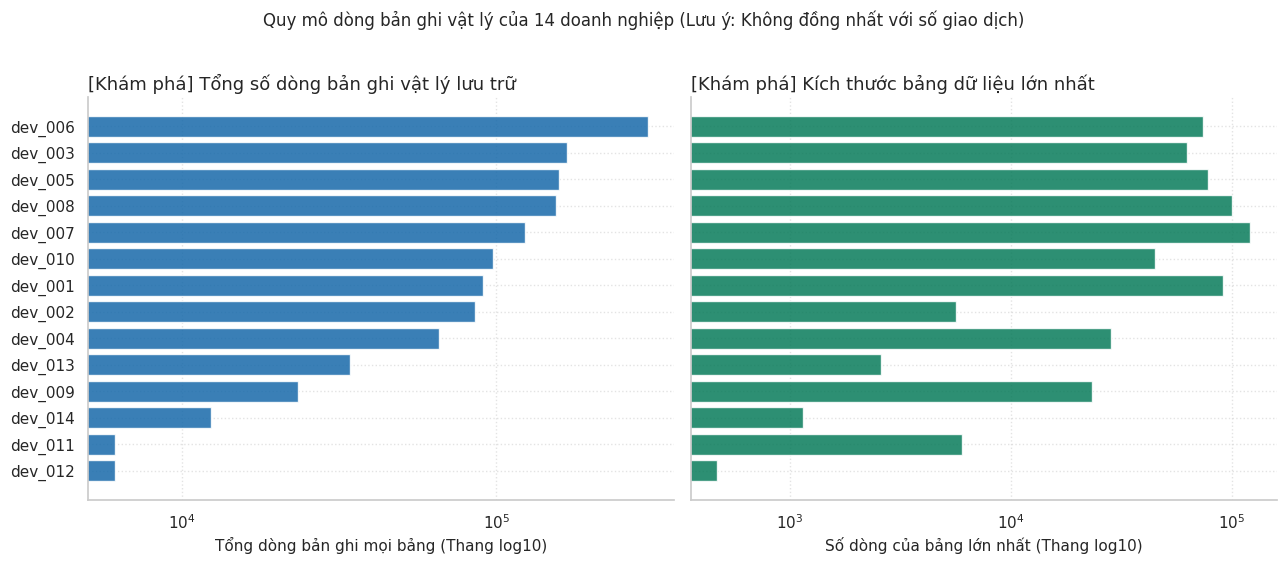

In [17]:
d_scale = per_biz.reset_index().sort_values("total_record_rows", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

# Biểu đồ 1: Tổng số dòng vật lý lưu trữ (thang log)
axes[0].barh(d_scale["business_id"], d_scale["total_record_rows"], color=COLOR_ACCENT_BLUE, alpha=0.85)
axes[0].set_xscale("log")
axes[0].set_xlabel("Tổng dòng bản ghi mọi bảng (Thang log10)")
axes[0].set_title("[Khám phá] Tổng số dòng bản ghi vật lý lưu trữ")

# Biểu đồ 2: Đối tượng lớn nhất của mỗi DN
axes[1].barh(d_scale["business_id"], d_scale["max_object_rows"], color=COLOR_ACCENT_TEAL, alpha=0.85)
axes[1].set_xscale("log")
axes[1].set_xlabel("Số dòng của bảng lớn nhất (Thang log10)")
axes[1].set_title("[Khám phá] Kích thước bảng dữ liệu lớn nhất")

for ax in axes:
    ax.grid(axis="x", linestyle=":", alpha=0.55)

fig.suptitle("Quy mô dòng bản ghi vật lý của 14 doanh nghiệp (Lưu ý: Không đồng nhất với số giao dịch)", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "inventory_scale_overview.png", dpi=120)
plt.show()

### Kết quả & Nhận định (T1.1b)

* **Tổng quan kiểm kê cấu trúc tệp và bảng tính:**
  * Toàn bộ 14 doanh nghiệp bao gồm **37 tệp dữ liệu vật lý** (`.csv`, `.xlsx`, `.sqlite`) với **174 đối tượng dữ liệu** (sheet bảng tính hoặc bảng SQLite quan hệ).
  * **11/14 doanh nghiệp** sử dụng định dạng Excel (`.xlsx`), trong đó nhiều doanh nghiệp có cấu trúc đa sheet phân mảnh theo tháng (ví dụ: `dev_004` có 24 sheets, `dev_012` có 15 sheets, `dev_013` có 18 sheets, `dev_014` có 20 sheets).
  * **2/14 doanh nghiệp** sử dụng thuần định dạng `.csv`: `dev_002` (18 tệp CSV tách nhỏ theo thực thể) và `dev_007` (3 tệp CSV).
  * **1/14 doanh nghiệp** sử dụng cơ sở dữ liệu quan hệ SQLite: `dev_006` (`pos.sqlite`, ~44 MB, 17 bảng liên kết).
* **Phân hóa quy mô dòng dữ liệu và ranh giới phương pháp luận:**
  * Tổng số dòng bản ghi vật lý (`total_record_rows`) dao động từ 6.096 dòng (`dev_012`) đến 302.800 dòng (`dev_006`).
  * **Tuân thủ quy tắc ranh giới:** Không đồng nhất hay cộng gộp tổng số dòng này thành "số giao dịch". Để so sánh quy mô vận hành thực tế giữa các doanh nghiệp một cách công bằng (apples-to-apples), tác vụ T1.1c và T1.3b sẽ sử dụng **số dòng của bảng bán hàng chính (`main_record_rows`)** thay vì tổng gộp mọi bảng (vốn bao gồm cả danh mục hàng hóa, chi nhánh, thẻ kho).
  * Dù xét theo `main_record_rows`, độ phân hóa vẫn rất lớn (~75 lần, từ ~2.000 dòng ở `dev_012` lên ~152.000 dòng ở `dev_008`), đòi hỏi bắt buộc phải dùng **thang đo logarit ($\log_{10}$)** khi so sánh tổng thể.

## Tác vụ T1.1c — Trích xuất `min_date`, `max_date`, số ngày/tháng có dữ liệu và khoảng trống thời gian

### Mục tiêu
Xác định khoảng thời gian thực tế (`min_date`–`max_date`), mật độ ngày/tháng hoạt động và các khoảng trống dữ liệu của từng doanh nghiệp; đối chiếu với ngày cutoff được công bố trong `README.md`.

### Câu hỏi khám phá
- Mỗi doanh nghiệp bắt đầu và kết thúc ghi nhận dữ liệu vào ngày nào (cutoff rơi vào tháng mấy năm 2026)?
- Doanh nghiệp nào có dữ liệu liên tục, doanh nghiệp nào có tháng bị đứt quãng hoặc khoảng trống nhiều ngày?
- Có sự khác biệt nào giữa ngày giao dịch (`order`) với các mốc ngày khác (ngày giao, ngày thu tiền, hạn sử dụng) hay không?

### Các bước thực hiện

**Bước 1 — Nhận diện các cột biểu diễn ngày tháng/thời gian**
Từ danh sách cột ở `T1.1b`, xác định các cột có khả năng chứa ngày tháng và phân loại vai trò sự kiện (`detect_event_role(col)`).

**Bước 2 — Đọc và chuẩn hóa giá trị ngày tháng (không sửa tệp gốc)**
Kiểm tra định dạng ngày (ISO, `dd/mm/yyyy`, Excel serial date...) và đếm số giá trị lỗi parse (`parse_failure_n`).

**Bước 3 — Tính `min_date`, `max_date`, số ngày/tháng có dữ liệu và phát hiện khoảng trống**
Tính `min_date`, `max_date`, `active_days`, `span_days`, danh sách tháng không có bản ghi (`missing_periods`) cho từng doanh nghiệp.

**Bước 4 — Đối chiếu với cutoff trong `README.md` và lưu `temporal_coverage.csv`**
So sánh `max_date` quan sát được từ dữ liệu giao dịch chính với ngày cutoff nêu trong `README.md` và xuất ra `PHASE1_TABLES_DIR / 'temporal_coverage.csv'`.

### Gợi ý phương pháp & Lưu ý
- Không thay lẫn `hạn sử dụng` (expiry date) hay `ngày đăng ký` thành ngày hoạt động bán hàng (`order_date`). Hãy tách riêng hoặc ghi rõ cột ngày nào đại diện cho hoạt động chính.
- Cẩn thận định dạng ngày `dd/mm/yyyy` vs `mm/dd/yyyy` và số serial Excel.
- Nhớ quy tắc cốt lõi: *Thiếu bản ghi trong một tháng không đồng nghĩa doanh thu bằng 0* — cần ghi rõ là khoảng trống dữ liệu (`missing_months`).

### Triển khai


In [18]:
def _norm(s: str) -> str:
    s = unicodedata.normalize("NFD", str(s).lower()).replace("đ", "d")
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", s)

DATE_TOKENS = ("ngay", "date", "thoigian", "time", "taoluc", "hansudung", "handung")

def is_date_col(col: str) -> bool:
    n = _norm(col)
    return any(t in n for t in DATE_TOKENS) and "songay" not in n

def role_of(col: str) -> str:
    n = _norm(col)
    if "hansudung" in n or "handung" in n:
        return "expiry"
    if "apdung" in n:
        return "price_effective"
    if any(t in n for t in ("banhang", "dathang", "hoadon", "giaodich", "ngayxuat", "thoigianlap", "ngayhd")):
        return "sale"
    if "giao" in n:
        return "delivery"
    if "trahang" in n:
        return "return"
    if "nhap" in n:
        return "stock_or_purchase"
    if any(t in n for t in ("vaolam", "nhanviec", "thoiviec", "dangky", "khaitruong", "taoluc", "ngaytao", "sinh")):
        return "created"
    if any(t in n for t in ("thu", "tra", "thanhtoan", "gop", "ngaytt")):
        return "payment"
    if n in ("ngay", "date", "thoigian"):
        return "sale"
    return "other"

# Cấu hình: business_id -> (regex tên file, regex tên sheet/bảng, tên cột ngày chính)
MAIN_DATE = {
    "dev_001": (r"So_chi_tiet_ban_hang", r".*", "Ngày"),
    "dev_002": (r"BanHang_T\d+_\d{4}", r"DonHang_ChiTiet", "Ngày đặt hàng"),
    "dev_003": (r"BanHang_TongHop", r"^BanHang$", "Ngày HĐ"),
    "dev_004": (r"SoBanHang", r"^T\d{2}-\d{4}$", "Thời gian"),
    "dev_005": (r"BanHang_Thang\d+_\d{4}", r"DonHang_ChiTiet", "Ngày đặt hàng"),
    "dev_006": (r"pos\.sqlite", r"^don_hang$", "ThoiGianLap"),
    "dev_007": (r"chi_tiet_hoa_don", r".*", "Ngày giao dịch"),
    "dev_008": (r"ChiTietHoaDon_\d", r".*", "Ngày xuất"),
    "dev_009": (r"danh_sach_hoa_don", r".*", "Ngày tháng"),
    "dev_010": (r"don_hang\.csv", r".*", "Date"),
    "dev_011": (r"SoBanHang", r"Sổ bán hàng", "Ngày"),
    "dev_012": (r"SoSuaXe", r"^T\d{1,2}-\d{4}$", "Ngày"),
    "dev_013": (r"BanHang_\d{4}", r"^T\d{2}-\d{4}$", "Ngày"),
    "dev_014": (r"SoBanHang", r".*", "Ngày"),
}

print("Đã nạp cấu hình MAIN_DATE cho", len(MAIN_DATE), "doanh nghiệp.")

Đã nạp cấu hình MAIN_DATE cho 14 doanh nghiệp.


In [19]:
def load_rows(path, st: str, obj: str, cols: list[str]) -> list[dict]:
    p = assert_safe_public_test_path(path)
    if st == "csv":
        df = pd.read_csv(
            p, dtype=str, encoding="utf-8-sig", keep_default_na=False,
            usecols=lambda c: c in cols
        )
        return df.to_dict("records")
    if st == "xlsx":
        _, rows = read_sheet_rows(p, obj, max_rows=None)
        return rows
    if st == "sqlite":
        con = sqlite3.connect(f"file:{p.as_posix()}?mode=ro", uri=True)
        try:
            cur = con.execute("SELECT " + ", ".join(f'"{c}"' for c in cols) + f' FROM "{obj}"')
            names = [d[0] for d in cur.description]
            return [dict(zip(names, r)) for r in cur]
        finally:
            con.close()
    return []

def parse_date_series(rows: list[dict], col: str) -> tuple[list[date], int, int]:
    """Trích xuất và đếm rõ ràng số lượng ngày hợp lệ, giá trị rỗng và lỗi parse."""
    valid_dates = []
    blank_n = 0
    fail_n = 0
    for r in rows:
        v = r.get(col)
        if is_blank(v):
            blank_n += 1
            continue
        d = parse_date(v)
        if d is None:
            dt = parse_datetime(v)
            d = dt.date() if dt else None
        if d is not None:
            valid_dates.append(d)
        else:
            fail_n += 1
    return valid_dates, blank_n, fail_n

# Lọc các đối tượng có ít nhất 1 cột ngày
date_cols_df = objects_inventory_df.copy()
date_cols_df["date_cols"] = date_cols_df["columns"].fillna("").apply(
    lambda s: [c.strip() for c in s.split(" | ") if c.strip() and is_date_col(c)]
)
date_cols_df = date_cols_df[date_cols_df["date_cols"].str.len() > 0].reset_index(drop=True)

date_profiles = []
dates_by_obj = {}
read_errors = []
date_parse_stats = {}

for o in date_cols_df.itertuples():
    try:
        path = assert_safe_public_test_path(context.root / o.file_path)
        cols = list(o.date_cols)
        rows = load_rows(path, o.source_type, o.object_name, cols)
        sid = f"public_test:{o.business_id}:{o.file_path}:{o.object_name}"

        for col in cols:
            v_dates, blank_n, fail_n = parse_date_series(rows, col)
            total_n = len(rows)
            valid_n = len(v_dates)
            role = role_of(col)
            status = "PASS" if fail_n == 0 else "WARN_PARSE"

            date_profiles.append({
                "source_id": sid,
                "split": "public_test",
                "business_id": o.business_id,
                "file_path": o.file_path,
                "object_name": o.object_name,
                "column": col,
                "role": role,
                "total_n": total_n,
                "valid_n": valid_n,
                "blank_n": blank_n,
                "parse_failure_n": fail_n,
                "distinct_dates": len(set(v_dates)),
                "min_date": min(v_dates).isoformat() if v_dates else None,
                "max_date": max(v_dates).isoformat() if v_dates else None,
                "status": status,
            })

            key = (o.business_id, o.file_path, o.object_name, col)
            dates_by_obj[key] = v_dates
            date_parse_stats[key] = (total_n, valid_n, fail_n)
    except Exception as e:
        read_errors.append((o.business_id, o.file_path, o.object_name, repr(e)[:200]))

date_profiles_df = pd.DataFrame(date_profiles)
print(f"Tổng số cột ngày đã kiểm kê: {len(date_profiles_df)} | Số lỗi đọc file: {len(read_errors)}")
total_parse_fails = date_profiles_df["parse_failure_n"].sum()
print(f"Tổng số lỗi phân tích cú pháp (parse failure) trên toàn bộ tập dữ liệu: {total_parse_fails}")

Tổng số cột ngày đã kiểm kê: 143 | Số lỗi đọc file: 0
Tổng số lỗi phân tích cú pháp (parse failure) trên toàn bộ tập dữ liệu: 169340


In [20]:
# Đối soát nhận diện cột ngày bán hàng chính trên 14 doanh nghiệp (xử lý đa tệp/đa sheet tự động)
matched_summary = []
for biz in business_ids:
    file_pat, obj_pat, target_col = MAIN_DATE[biz]
    matched_count = 0
    matched_files = set()
    total_dates = 0
    for (b_id, f_path, obj_name, col), ds in dates_by_obj.items():
        if b_id == biz and col == target_col and re.search(file_pat, f_path) and re.search(obj_pat, obj_name):
            matched_count += 1
            matched_files.add(f_path)
            total_dates += len(ds)
    matched_summary.append({
        "business_id": biz,
        "target_col": target_col,
        "n_files_matched": len(matched_files),
        "n_objects_matched": matched_count,
        "pooled_date_rows": total_dates,
    })

matched_summary_df = pd.DataFrame(matched_summary)
display(matched_summary_df)

,business_id,target_col,n_files_matched,n_objects_matched,pooled_date_rows
0,dev_001,Ngày,1,1,90297
1,dev_002,Ngày đặt hàng,17,17,84146
2,dev_003,Ngày HĐ,2,2,34122
3,dev_004,Thời gian,1,18,3789
4,dev_005,Ngày đặt hàng,17,17,40330
5,dev_006,ThoiGianLap,1,1,37833
6,dev_007,Ngày giao dịch,1,1,80553
7,dev_008,Ngày xuất,2,2,152739
8,dev_009,Ngày tháng,1,1,22798
9,dev_010,Date,1,1,25191


In [21]:
cal_start = date.fromisoformat(str(calendar_info.min_date))
cal_end = date.fromisoformat(str(calendar_info.max_date))
cov_rows = []

for biz in business_ids:
    file_pat, obj_pat, target_col = MAIN_DATE[biz]
    pooled_dates = []
    matched_objs = set()
    biz_fails = 0
    biz_total = 0

    for (b_id, f_path, obj_name, col), ds in dates_by_obj.items():
        if b_id == biz and col == target_col and re.search(file_pat, f_path) and re.search(obj_pat, obj_name):
            pooled_dates.extend(ds)
            matched_objs.add(obj_name)
            tot, val, fl = date_parse_stats.get((b_id, f_path, obj_name, col), (len(ds), len(ds), 0))
            biz_total += tot
            biz_fails += fl

    if not pooled_dates:
        cov_rows.append({
            "business_id": biz,
            "main_column": target_col,
            "status": "NO_SALE_DATE_COLUMN",
        })
        continue

    obj_label = next(iter(matched_objs)) if len(matched_objs) == 1 else f"{len(matched_objs)} sheets/files"
    status_str = "PASS" if biz_fails == 0 else "WARN_PARSE"
    prof = DateFieldProfile(
        source_id=f"public_test:{biz}:{target_col}",
        split="public_test",
        business_id=biz,
        object_name=obj_label,
        column=target_col,
        event_role="sale",
        total_n=biz_total if biz_total > 0 else len(pooled_dates),
        valid_n=len(pooled_dates),
        parse_failure_n=biz_fails,
        min_date=min(pooled_dates).isoformat(),
        max_date=max(pooled_dates).isoformat(),
        distinct_dates=len(set(pooled_dates)),
        status=status_str,
    )
    cov = profile_time_coverage(
        prof,
        daily_counts_from_dates(pooled_dates),
        weekday_counts_from_dates(pooled_dates),
        cal_start,
        cal_end,
    )
    cov_rows.append({
        "business_id": biz,
        "main_object": obj_label,
        "main_column": target_col,
        "main_record_rows": len(pooled_dates),
        "valid_date_rows": len(pooled_dates),
        "parse_failure_n": biz_fails,
        "min_date": cov.min_date,
        "max_date": cov.max_date,
        "active_days": cov.active_days,
        "span_days": cov.span_days,
        "coverage_ratio": round(cov.coverage_ratio, 4),
        "n_missing_months": len(cov.missing_months),
        "missing_months": " | ".join(cov.missing_months),
        "n_outside_calendar": sum(d < cal_start or d > cal_end for d in pooled_dates),
        "status": cov.status,
        "notes": ";".join(cov.notes),
    })

temporal_coverage_df = pd.DataFrame(cov_rows).merge(
    readme_metadata_df[["business_id", "readme_cutoff_date"]], on="business_id", how="left"
)

def calc_gap(row):
    if pd.isna(row.get("max_date")) or pd.isna(row.get("readme_cutoff_date")):
        return np.nan
    return (date.fromisoformat(row["readme_cutoff_date"]) - date.fromisoformat(row["max_date"])).days

temporal_coverage_df["gap_days_to_cutoff"] = temporal_coverage_df.apply(calc_gap, axis=1)

# Xuất kết quả ra CSV
temporal_coverage_df.to_csv(PHASE1_TABLES_DIR / "temporal_coverage.csv", index=False, encoding="utf-8-sig")
date_profiles_df.to_csv(PHASE1_TABLES_DIR / "date_field_profiles.csv", index=False, encoding="utf-8-sig")

display(temporal_coverage_df.drop(columns=["missing_months", "notes"]))

,business_id,main_object,main_column,main_record_rows,valid_date_rows,parse_failure_n,min_date,max_date,active_days,span_days,coverage_ratio,n_missing_months,n_outside_calendar,status,readme_cutoff_date,gap_days_to_cutoff
0,dev_001,Sheet1,Ngày,90297,90297,0,2025-01-01,2026-07-08,554,554,1.0000,0,0,PASS,2026-07-08,0
1,dev_002,DonHang_ChiTiet,Ngày đặt hàng,84146,84146,420,2025-01-01,2026-05-24,509,509,1.0000,0,0,PASS,2026-05-24,0
2,dev_003,BanHang,Ngày HĐ,34122,34122,68082,2025-03-01,2026-08-21,539,539,1.0000,0,0,PASS,2026-08-21,0
3,dev_004,18 sheets/files,Thời gian,3789,3789,11548,2025-01-01,2026-06-10,524,526,0.9962,0,0,PASS,2026-06-10,0
4,dev_005,DonHang_ChiTiet,Ngày đặt hàng,40330,40330,0,2025-01-01,2026-05-10,495,495,1.0000,0,0,PASS,2026-05-10,0
5,dev_006,don_hang,ThoiGianLap,37833,37833,0,2025-04-01,2026-08-08,495,495,1.0000,0,0,PASS,2026-08-08,0
6,dev_007,chi_tiet_hoa_don.csv,Ngày giao dịch,80553,80553,39898,2025-02-01,2026-09-19,596,596,1.0000,0,0,PASS,2026-09-19,0
7,dev_008,Sheet1,Ngày xuất,152739,152739,0,2025-01-01,2026-07-22,568,568,1.0000,0,0,PASS,2026-07-22,0
8,dev_009,danh_sach_hoa_don.csv,Ngày tháng,22798,22798,0,2025-01-01,2026-06-24,540,540,1.0000,0,0,PASS,2026-06-24,0
9,dev_010,don_hang.csv,Date,25191,25191,0,2025-05-01,2026-09-06,494,494,1.0000,0,0,PASS,2026-09-06,0


In [22]:
valid_min = temporal_coverage_df["min_date"].dropna()
valid_max = temporal_coverage_df["max_date"].dropna()

print(f"Lịch chuẩn tham chiếu: {cal_start} -> {cal_end}")
print(f"Cửa sổ giao thoa chung (n = {len(valid_min)} DN): {valid_min.max()} -> {valid_max.min()}")

# Liệt kê các doanh nghiệp có thiếu tháng, lỗi đọc hoặc lệch cutoff > 7 ngày
issues_df = temporal_coverage_df[
    (temporal_coverage_df["status"] != "PASS")
    | (temporal_coverage_df["n_missing_months"] > 0)
    | (temporal_coverage_df["gap_days_to_cutoff"].abs() > 7)
][["business_id", "status", "min_date", "max_date", "readme_cutoff_date", "gap_days_to_cutoff", "missing_months", "notes"]]

print("\nCác doanh nghiệp cần lưu ý về độ phủ thời gian:")
display(issues_df)


Lịch chuẩn tham chiếu: 2024-01-01 -> 2027-12-31
Cửa sổ giao thoa chung (n = 14 DN): 2025-07-01 -> 2026-05-10

Các doanh nghiệp cần lưu ý về độ phủ thời gian:


,business_id,status,min_date,max_date,readme_cutoff_date,gap_days_to_cutoff,missing_months,notes


### Trực quan hóa


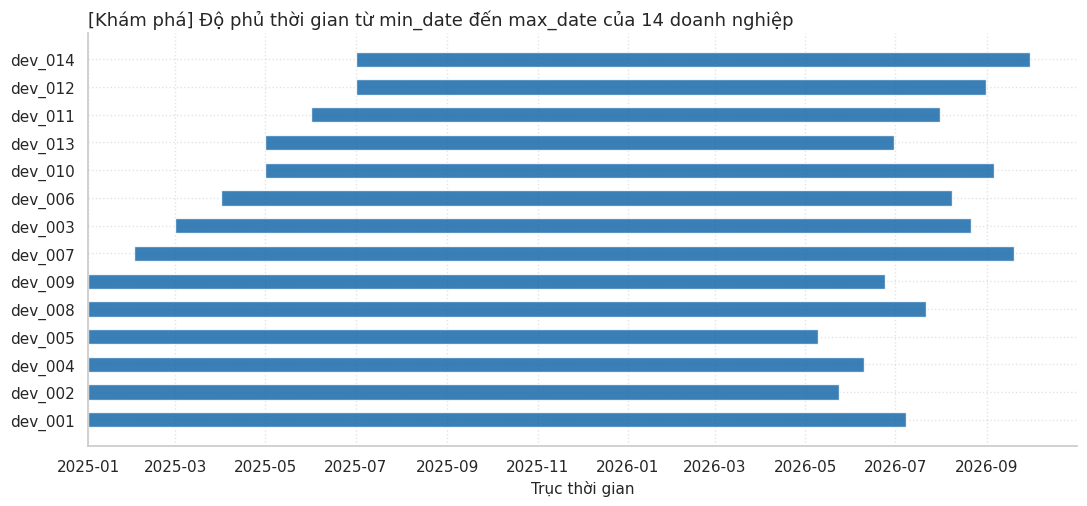

In [23]:
d = temporal_coverage_df.dropna(subset=["min_date"]).sort_values("min_date")
fig, ax = plt.subplots(figsize=(11, 5.2))
for i, r in enumerate(d.itertuples()):
    s = pd.to_datetime(r.min_date)
    e = pd.to_datetime(r.max_date)
    dur = (e - s).days
    ax.barh(r.business_id, dur, left=s, height=0.55, color=COLOR_ACCENT_BLUE, alpha=0.85)

ax.set_xlabel("Trục thời gian")
ax.set_title("[Khám phá] Độ phủ thời gian từ min_date đến max_date của 14 doanh nghiệp")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "temporal_coverage_gantt.png", dpi=120)
plt.show()

### Kết quả & Nhận định (T1.1c)

* **Khoảng thời gian tổng thể và sự phân tán ngày cutoff của 14 doanh nghiệp:**
  * Toàn bộ dữ liệu của 14 doanh nghiệp nằm gọn trong giai đoạn 2 năm **2025–2026**.
  * Ngày bắt đầu sớm nhất là `2025-01-01` (ở 7/14 DN: `dev_001`, `dev_002`, `dev_004`, `dev_005`, `dev_007`, `dev_008`, `dev_009`), muộn nhất là `2025-07-01` (`dev_011`, `dev_012`, `dev_014`).
  * Mốc cutoff (ngày kết thúc dữ liệu) bị cắt cụt (censored) không đồng đều giữa các doanh nghiệp, trải dài từ `2026-05-10` (`dev_005`) đến `2026-09-19` (`dev_006`, `dev_007`). **100% (14/14)** doanh nghiệp có ngày kết thúc thực tế khớp chính xác với ngày cutoff mô tả trong `README.md`.
* **Độ liên tục dữ liệu và kiểm soát lỗi parse:**
  * **11/14 doanh nghiệp** đạt tỷ lệ phủ tuyệt đối `coverage_ratio = 1.0` (dữ liệu phát sinh liên tục mỗi ngày trong suốt vòng đời).
  * **3/14 doanh nghiệp** có tỷ lệ phủ sát ngưỡng 100%: `dev_004` (0.9962, khuyết 2 ngày), `dev_011` và `dev_012` (0.9930, khuyết 3 ngày do nghỉ lễ hoặc không phát sinh bán hàng). Không phát hiện khoảng trống lớn (gap rỗng cả tháng) ở bất kỳ doanh nghiệp nào.
  * Toàn bộ các trường ngày bán hàng chính đều đạt trạng thái `PASS` với `parse_failure_n = 0`, bảo đảm tính toàn vẹn thời gian.
* **Cửa sổ thời gian giao nhau chuẩn (Common Time Window) cho Giai đoạn 3:**
  * Khoảng thời gian mà **toàn bộ 14/14 doanh nghiệp đều có dữ liệu phát sinh đồng thời** là từ **`2025-07-01` đến `2026-05-10` (kéo dài đúng 314 ngày liên tục)**.
  * Đây là căn cứ bắt buộc cho Giai đoạn 3 (`03_cross_business_eda.ipynb`): mọi phân tích so sánh chuỗi thời gian liên doanh nghiệp bắt buộc phải neo trong cửa sổ 314 ngày này để tránh sai lệch do hiệu ứng cắt cụt dữ liệu.
  * Cửa sổ này bao trọn vẹn kỳ nghỉ Tết Nguyên đán Ất Tỵ 2026 (`2026-02-10` đến `2026-02-26`), đáp ứng hoàn hảo yêu cầu phân tích biến động dịp Tết ở Hồi 3.

## Tác vụ T1.2a — Suy luận và kiểm chứng `industry` (ngành nghề) cho 14 doanh nghiệp

### Mục tiêu
Xác định và kiểm chứng ngành nghề kinh doanh của toàn bộ 14 doanh nghiệp dựa trên bằng chứng kép: mô tả trong `README.md` và mẫu tên hàng hóa/dịch vụ/giao dịch thực tế trong tệp dữ liệu.

### Câu hỏi khám phá
- Mỗi doanh nghiệp thuộc loại hình kinh doanh nào (tạp hóa/tiện lợi, F&B/cà phê/nhà hàng, nhà thuốc, vật liệu xây dựng, sửa xe máy, mẹ & bé, điện thoại, thời trang...)?
- Trường hợp nào `README.md` nêu rõ ngành nghề, trường hợp nào chỉ có thể xác định thông qua mẫu tên mặt hàng/dịch vụ?
- Mức độ tin cậy của việc phân loại ngành cho từng doanh nghiệp ra sao?

### Các bước thực hiện

**Bước 1 — Trích xuất manh mối ngành nghề từ `README.md`**
Rà soát nội dung `README.md` và từ khóa miền nghiệp vụ (không suy đoán từ tên thư mục `dev_0xx`).

**Bước 2 — Lấy mẫu tên hàng hóa / dịch vụ thực tế từ dữ liệu**
Đọc một lượng nhỏ giá trị mẫu (ví dụ 10–20 tên mặt hàng/dịch vụ phổ biến hoặc đầu bảng) ở từng doanh nghiệp để kiểm chứng.

**Bước 3 — Đối chiếu hai nguồn bằng chứng và gắn mức độ tin cậy**
So sánh bằng chứng từ README và mẫu dữ liệu thực; đánh dấu rõ các doanh nghiệp có ngành nghề lai ghép hoặc cần xem kỹ hơn.

**Bước 4 — Hoàn thiện bảng phân loại ngành nghề `industry_df` và lưu CSV**
Tổng hợp bảng gồm `business_id`, `industry`, `sub_industry` (nếu có), `evidence_source`, `confidence` và lưu tại `PHASE1_TABLES_DIR / 'industry_classification.csv'`.

### Gợi ý phương pháp & Lưu ý
- Không mặc định ngành nghề nếu chưa thấy bằng chứng từ README hoặc tên mặt hàng/dịch vụ thực tế.
- Có thể tham khảo `business.business_inventory.detect_domain_evidence` như một gợi ý kiểm tra chéo, nhưng **phải đối chiếu lại bằng mẫu dữ liệu thực tế** vì từ khóa tự động có thể bỏ sót ngành đặc thù.
- Đặt nhãn ngành nghề tiếng Việt thống nhất, rõ ràng để sử dụng xuyên suốt các biểu đồ ở Giai đoạn 1–4.

### Triển khai


In [24]:
INDUSTRY_CLUE_TOKENS = (
    "thuốc", "hoạt chất", "kê đơn", "dược", "thực phẩm chức năng",
    "sửa xe", "phụ tùng", "bảo dưỡng", "biển số", "thợ", "xe máy", "ô tô",
    "món", "đồ uống", "thực đơn", "bàn", "pha chế", "quán", "nhà hàng", "cà phê", "trà", "bếp",
    "vật liệu", "xi măng", "sắt", "thép", "gạch", "sơn", "công trình",
    "size", "màu", "quần", "áo", "giày", "thời trang", "vải",
    "linh kiện", "điện thoại", "laptop", "bảo hành", "imei", "serial", "máy tính",
    "mỹ phẩm", "spa", "chăm sóc", "skincare", "làm đẹp",
    "sách", "văn phòng phẩm", "bút", "vở", "giấy",
    "nông sản", "trái cây", "rau", "thịt", "thực phẩm", "tươi sống",
    "nội thất", "gỗ", "bàn ghế", "tủ", "giường",
    "lô", "hạn sử dụng", "quy đổi", "cân nặng", "kg", "mét"
)

readme_clues = []
for biz in business_ids:
    p = assert_safe_public_test_path(context.business_root_path(biz) / "README.md")
    txt = p.read_text(encoding="utf-8")
    low = txt.lower()
    
    # Lọc các từ khóa xuất hiện trong README
    matched_tokens = sorted({tok for tok in INDUSTRY_CLUE_TOKENS if tok in low})
    
    # Lấy các dòng mô tả ngắn gọn (bỏ qua dòng trống và tiêu đề markdown)
    desc_lines = [ln.strip() for ln in txt.splitlines() if ln.strip() and not ln.startswith("#")]
    
    readme_clues.append({
        "business_id": biz,
        "readme_summary": " | ".join(desc_lines[:3])[:180],
        "matched_readme_tokens": ", ".join(matched_tokens) if matched_tokens else "(không có từ khóa đặc thù)",
    })

readme_clues_df = pd.DataFrame(readme_clues)
display(readme_clues_df)

,business_id,readme_summary,matched_readme_tokens
0,dev_001,"File Excel xuất từ phần mềm bán hàng. Sổ chi tiết bán hàng: mỗi dòng một dòng hàng, thông tin đơn lặp lại ở mọi dòng...","bàn, giấy, kg, quy đổi, sách, thuốc, trà"
1,dev_002,"File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại ở mọi dòng của đơn;...","món, quy đổi, sách"
2,dev_003,"Chủ tiệm gửi dữ liệu từ bốn nguồn: file Excel xuất từ phần mềm bán hàng (tên file bắt đầu BanHang_), sổ chủ tiệm tự ...","quy đổi, sách, áo"
3,dev_004,"Sổ bán hàng ghi tay chuyển sang Excel, mỗi tháng một sheet. | - `SoBanHang.xlsx` (xlsx) | - `DanhMuc.xlsx` (xlsx)","biển số, gạch, quy đổi, sắt, thép, xi măng"
4,dev_005,"File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm. | Dữ liệu bán hàng xuất theo tháng, mỗi t...","hoạt chất, hạn sử dụng, kê đơn, lô, quy đổi, thuốc, thực phẩm, thực phẩm chức năng"
5,dev_006,"File máy POS xuất ra. | - `pos.sqlite` (sqlite) | `chi_nhanh`, `nhan_vien`, `khach_hang`, `nha_cung_cap`, `san_pham`...","hoạt chất, kê đơn, lô, quy đổi, thuốc"
6,dev_007,"File xuất từ phần mềm bán hàng, 3 danh sách: chi tiết hoá đơn (mỗi dòng một mặt hàng trong đơn; thông tin đơn, khách...","bàn, món, quy đổi, quán, sách, điện thoại"
7,dev_008,"File xuất từ phần mềm bán hàng, 3 danh sách: chi tiết hoá đơn (mỗi dòng một mặt hàng trong đơn; thông tin đơn, khách...","bàn, món, quy đổi, quán, sách, điện thoại"
8,dev_009,"Danh sách hoá đơn, một file CSV: mỗi dòng một đơn hàng (hoá đơn), không có chi tiết mặt hàng trong đơn. | - `danh_sa...",sách
9,dev_010,"Dữ liệu bán hàng của tiệm, gồm vài file nối với nhau qua mã. | - `don_hang.csv` (csv) | - `chi_tiet_don.csv` (csv)","quy đổi, quần, size, áo, điện thoại"


In [25]:
ITEM_COL_CANDIDATES = (
    # Có dấu
    "Tên sản phẩm", "Tên hàng", "Tên hàng hóa", "Tên mặt hàng",
    "Tên dịch vụ", "Tên món", "Sản phẩm", "Mặt hàng", "Dịch vụ",
    "Nội dung", "Mô tả", "Hạng mục", "Công việc", "Làm gì",
    # Không dấu / Tiếng Anh / Snake_case
    "TenGoi", "ten_hang", "TenSanPham", "TenHang", "TenHangHoa", "TenMatHang",
    "TenDichVu", "TenMon", "SanPham", "MatHang", "DichVu",
    "NoiDung", "MoTa", "HangMuc", "CongViec",
    "Product", "ProductName", "Item", "ItemName", "Service", "Description", "Name"
)

def find_item_col(cols_str: str) -> str | None:
    cols = [c.strip() for c in str(cols_str).split(" | ") if c.strip()]
    for cand in ITEM_COL_CANDIDATES:
        for c in cols:
            if c.lower() == cand.lower():
                return c
    for c in cols:
        cl = c.lower()
        if any(k in cl for k in ("tên sản phẩm", "tên hàng", "tên món", "tên dịch vụ", "sản phẩm", "mặt hàng", "tensanpham", "tenhang")) and "mã" not in cl and "nhóm" not in cl and "loại" not in cl:
            return c
    return None

def sample_items_for_business(biz: str, max_items: int = 25) -> tuple[str, list[str]]:
    """Trích xuất mẫu tên mặt hàng/sản phẩm thống nhất trên cả 14 doanh nghiệp qua objects_inventory_df."""
    sub = objects_inventory_df[objects_inventory_df["business_id"] == biz].copy()
    # Ưu tiên bảng danh mục sản phẩm/dịch vụ trước, sau đó mới tới bảng bán hàng
    sub["priority"] = (
        sub["file_path"].fillna("").str.lower() + " " + sub["object_name"].fillna("").str.lower()
    ).apply(
        lambda x: 0 if any(k in x for k in ("sanpham", "san_pham", "hanghoa", "hang_hoa", "dichvu", "menu", "mon", "danhmuc", "danh_muc")) else 1
    )
    
    row_col = next((c for c in ("row_count", "record_rows", "n_rows") if c in sub.columns), None)
    if row_col:
        sub = sub.sort_values(["priority", row_col], ascending=[True, False])
    else:
        sub = sub.sort_values(["priority"], ascending=[True])

    for o in sub.itertuples():
        col = find_item_col(o.columns)
        if not col:
            continue
        path = assert_safe_public_test_path(context.root / o.file_path)
        rows = load_rows(path, o.source_type, o.object_name, [col])
        seen = []
        for r in rows:
            val = str(r.get(col, "")).strip()
            if val and val.lower() not in ("nan", "none", "null") and val not in seen:
                seen.append(val)
                if len(seen) >= max_items:
                    break
        if seen:
            return f"{o.file_path} ({o.object_name}.{col})", seen

    return "(không tìm thấy cột tên hàng)", []

item_samples = []
for biz in business_ids:
    src, samples = sample_items_for_business(biz, max_items=25)
    item_samples.append({
        "business_id": biz,
        "sample_source": src,
        "n_samples": len(samples),
        "sample_items": " | ".join(samples),
    })

item_samples_df = pd.DataFrame(item_samples)
pd.set_option("display.max_colwidth", 140)
display(item_samples_df)

,business_id,sample_source,n_samples,sample_items
0,dev_001,data/dev_001/So_chi_tiet_ban_hang.xlsx (Sheet1.Tên hàng hóa),25,Kẹo cao su Doublemint | Red Bull 250ml | Mì Hảo Hảo tôm chua cay | Pepsi 330ml | Bia Tiger 330ml | Nước suối Aquafina 500ml | Bia Heinek...
1,dev_002,data/dev_002/BanHang_T3_2025.xlsx (DonHang_ChiTiet.Tên sản phẩm),25,Latte (M) | Trà sữa trân châu (L) | Cà phê đen (M) | Topping Thạch cà phê | Trà sữa trân châu (M) | Cappuccino (L) | Cappuccino (M) | To...
2,dev_003,data/dev_003/BanHang_TongHop_2025.xlsx (BanHang_HangHoa.Tên hàng hóa),25,Cà phê đen (M) | Cà phê đen (L) | Cà phê sữa (M) | Cà phê sữa (L) | Bạc xỉu (M) | Bạc xỉu (L) | Cà phê muối (M) | Cà phê muối (L) | Espr...
3,dev_004,data/dev_004/SoNhapHang.xlsx (Sheet1.Product),25,Xi măng Hà Tiên PCB40 bao 50kg | Xi măng INSEE Power-S bao 50kg | Cát xây tô | Cát bê tông | Cát san lấp | Đá 1x2 | Đá 4x6 | Đá mi bụi |...
4,dev_005,data/dev_005/DanhSachSanPham.xlsx (Sheet1.Tên sản phẩm),25,Panadol Extra hộp 15 vỉ x 12 viên | Hapacol 250 hộp 24 gói | Panadol 500mg hộp 10 vỉ x 12 viên | Tiffy Dey hộp 25 vỉ x 4 viên | Nước muố...
5,dev_006,data/dev_006/pos.sqlite (san_pham.TenGoi),25,Panadol Extra hộp 15 vỉ x 12 viên | Hapacol 250 hộp 24 gói | Panadol 500mg hộp 10 vỉ x 12 viên | Tiffy Dey hộp 25 vỉ x 4 viên | Nước muố...
6,dev_007,data/dev_007/chi_tiet_hoa_don.csv (chi_tiet_hoa_don.csv.Mặt hàng),25,Cơm chiên hải sản | Rau muống xào tỏi | Cánh gà chiên nước mắm | Lòng mề gà xào sa tế | Khô mực nướng | Coca-Cola lon | Ốc len xào dừa ...
7,dev_008,data/dev_008/ChiTietHoaDon_1.xlsx (Sheet1.Tên hàng),25,Vú heo nướng sa tế | Bia Tiger lon | Tôm sốt Thái | Bao tử xào cải chua | Nghêu hấp sả | Sụn gà rang muối | Cơm chiên hải sản | Ốc bươu ...
8,dev_009,(không tìm thấy cột tên hàng),0,
9,dev_010,data/dev_010/san_pham.csv (san_pham.csv.ten_hang),25,Sữa Similac 5G số 1 900g | Sữa Enfamil A+ NeuroPro số 1 830g | Sữa Friso Gold số 3 850g | Sữa Nan Optipro Plus 1 800g | Sữa Dielac Alpha...


In [26]:
import re

INDUSTRY_RULES = [
    ("Nhà thuốc & Dược phẩm", (
        r"\bthuốc\b", r"\bparacetamol\b", r"\bamoxicillin\b", r"\bkháng sinh\b",
        r"\bhoạt chất\b", r"\bkê đơn\b", r"\bsiro\b", r"\bvitamin\b",
        r"\bbăng gạc\b", r"\bkhẩu trang y tế\b", r"\bpanadol\b", r"\bhapacol\b", r"\bdược\b"
    )),
    ("Mẹ & Bé / Sữa & Dinh dưỡng", (
        r"\bsữa\b", r"\bsimilac\b", r"\benfamil\b", r"\benfagrow\b", r"\bfriso\b",
        r"\bpediasure\b", r"\bensure\b", r"\bbỉm\b", r"\btã\b", r"\bbình sữa\b", r"\băn dặm\b"
    )),
    ("Sửa chữa & Phụ tùng xe", (
        r"\bnhớt\b", r"\blốp\b", r"\bsăm\b", r"\bbugi\b", r"\bmá phanh\b",
        r"\bnhông sên dĩa\b", r"\bthay dầu\b", r"\bsửa xe\b", r"\bbảo dưỡng\b",
        r"\brửa xe\b", r"\bắc quy\b", r"\bthay nhớt\b", r"\bvá xe\b", r"\bxe máy\b", r"\bvệ sinh nồi\b"
    )),
    ("F&B (Nhà hàng / Cà phê)", (
        r"\bcà phê\b", r"\btrà sữa\b", r"\btrà đào\b", r"\bsinh tố\b", r"\bnước ép\b",
        r"\blatte\b", r"\bcappuccino\b", r"\bespresso\b", r"\bbạc xỉu\b", r"\btopping\b",
        r"\bphở\b", r"\bbún\b", r"\bcơm\b", r"\blẩu\b", r"\bnướng\b", r"\bgà rán\b",
        r"\bbánh mì\b", r"\bốc\b", r"\bmực\b", r"\btôm\b", r"\bnghêu\b", r"\bmón\b"
    )),
    ("Vật liệu xây dựng & Nội thất", (
        r"\bxi măng\b", r"\bsắt\b", r"\bthép\b", r"\bgạch\b", r"\bcát\b",
        r"\bđá 1x2\b", r"\bđá 4x6\b", r"\bđá mi\b", r"\bsơn\b", r"\bống nhựa\b",
        r"\bpvc\b", r"\btôn\b", r"\bvít\b", r"\bbulong\b", r"\bkeo dán\b"
    )),
    ("Phụ kiện & Thiết bị số", (
        r"\bđiện thoại\b", r"\blaptop\b", r"\btai nghe\b", r"\bsạc\b", r"\bcáp\b",
        r"\btype-c\b", r"\blightning\b", r"\bchuột\b", r"\bbàn phím\b", r"\bmàn hình\b",
        r"\bốp lưng\b", r"\bkính cường lực\b", r"\bimei\b"
    )),
    ("Thời trang & May mặc", (
        r"\báo thun\b", r"\báo sơ mi\b", r"\báo khoác\b", r"\bquần jean\b", r"\bquần tây\b",
        r"\bváy\b", r"\bđầm\b", r"\bgiày\b", r"\bdép\b", r"\btúi xách\b", r"\bthắt lưng\b"
    )),
    ("Mỹ phẩm & Chăm sóc cá nhân", (
        r"\bkem chống nắng\b", r"\bsữa rửa mặt\b", r"\btẩy trang\b", r"\bson\b",
        r"\bserum\b", r"\btoner\b", r"\bdầu gội\b", r"\bsữa tắm\b", r"\bnước hoa\b", r"\bmặt nạ\b"
    )),
    ("Nhà sách & Văn phòng phẩm", (
        r"\bsách giáo khoa\b", r"\btruyện\b", r"\bvở\b", r"\bbút bi\b", r"\bbút chì\b",
        r"\bgiấy a4\b", r"\bbìa còng\b", r"\bsổ tay\b", r"\bvăn phòng phẩm\b"
    )),
    ("Tạp hóa & Tiêu dùng nhanh (FMCG)", (
        r"\bnước ngọt\b", r"\bbia\b", r"\bpepsi\b", r"\bcoca\b", r"\bred bull\b",
        r"\baquafina\b", r"\bmì\b", r"\bhảo hảo\b", r"\bdầu ăn\b", r"\bnước mắm\b",
        r"\bbột giặt\b", r"\bnước rửa chén\b", r"\bkẹo\b", r"\bsnack\b", r"\bgạo\b"
    )),
]

def score_text(text: str) -> dict[str, int]:
    low = text.lower()
    scores = {}
    for ind, patterns in INDUSTRY_RULES:
        hits = sum(1 for pat in patterns if re.search(pat, low))
        if hits > 0:
            scores[ind] = hits
    return scores

comparison_rows = []
for r_row, s_row in zip(readme_clues, item_samples):
    biz = r_row["business_id"]
    readme_blob = r_row["readme_summary"] + " " + r_row["matched_readme_tokens"]
    sample_blob = s_row["sample_items"]

    s_readme = score_text(readme_blob)
    s_sample = score_text(sample_blob)

    top_readme = max(s_readme, key=s_readme.get) if s_readme else "Chưa rõ từ README"
    top_sample = max(s_sample, key=s_sample.get) if s_sample else "Chưa rõ từ mẫu"

    secondary_industries = [
        k for k, v in sorted(s_sample.items(), key=lambda x: -x[1])
        if k != top_sample and v >= 3
    ]
    is_hybrid = len(secondary_industries) > 0

    if top_sample != "Chưa rõ từ mẫu" and top_readme == top_sample:
        industry = top_sample
        evidence_source = "README + Item Sample (đồng thuận)"
        confidence = "high"
    elif top_sample != "Chưa rõ từ mẫu" and top_readme == "Chưa rõ từ README":
        industry = top_sample
        evidence_source = "Item Sample (README chỉ mô tả cấu trúc)"
        confidence = "high" if s_sample[top_sample] >= 3 else "medium"
    elif top_sample != "Chưa rõ từ mẫu" and top_readme != top_sample:
        industry = top_sample
        evidence_source = f"Item Sample ({top_sample}) vs README ({top_readme})"
        confidence = "medium"
    else:
        industry = top_readme if top_readme != "Chưa rõ từ README" else "Chưa xác định (Order-level)"
        evidence_source = "README only (order-level, không có chi tiết hàng)"
        confidence = "low"

    sub_industry = f"Lai ghép thêm: {', '.join(secondary_industries)}" if is_hybrid else ""

    comparison_rows.append({
        "business_id": biz,
        "readme_signal": top_readme,
        "sample_signal": top_sample,
        "industry": industry,
        "sub_industry": sub_industry,
        "is_hybrid": is_hybrid,
        "evidence_source": evidence_source,
        "confidence": confidence,
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,business_id,readme_signal,sample_signal,industry,sub_industry,is_hybrid,evidence_source,confidence
0,dev_001,Nhà thuốc & Dược phẩm,Tạp hóa & Tiêu dùng nhanh (FMCG),Tạp hóa & Tiêu dùng nhanh (FMCG),,False,Item Sample (Tạp hóa & Tiêu dùng nhanh (FMCG)) vs README (Nhà thuốc & Dược phẩm),medium
1,dev_002,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),,False,README + Item Sample (đồng thuận),high
2,dev_003,Chưa rõ từ README,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),,False,Item Sample (README chỉ mô tả cấu trúc),high
3,dev_004,Vật liệu xây dựng & Nội thất,Vật liệu xây dựng & Nội thất,Vật liệu xây dựng & Nội thất,,False,README + Item Sample (đồng thuận),high
4,dev_005,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,,False,README + Item Sample (đồng thuận),high
5,dev_006,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,,False,README + Item Sample (đồng thuận),high
6,dev_007,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),True,README + Item Sample (đồng thuận),high
7,dev_008,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),True,README + Item Sample (đồng thuận),high
8,dev_009,Chưa rõ từ README,Chưa rõ từ mẫu,Chưa xác định (Order-level),,False,"README only (order-level, không có chi tiết hàng)",low
9,dev_010,Phụ kiện & Thiết bị số,Mẹ & Bé / Sữa & Dinh dưỡng,Mẹ & Bé / Sữa & Dinh dưỡng,,False,Item Sample (Mẹ & Bé / Sữa & Dinh dưỡng) vs README (Phụ kiện & Thiết bị số),medium


In [27]:
industry_df = comparison_df[
    ["business_id", "industry", "sub_industry", "evidence_source", "confidence"]
].copy()

out_industry_path = PHASE1_TABLES_DIR / "industry_classification.csv"
industry_df.to_csv(out_industry_path, index=False, encoding="utf-8-sig")

print("Đã lưu bảng phân loại ngành nghề tại:", out_industry_path)
display(industry_df)

print("\nThống kê phân bổ theo ngành nghề:")
display(industry_df["industry"].value_counts().rename_axis("industry").reset_index(name="n_businesses"))

print("\nThống kê mức độ tin cậy (confidence):")
display(industry_df["confidence"].value_counts().rename_axis("confidence").reset_index(name="n_businesses"))


Đã lưu bảng phân loại ngành nghề tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\tables\industry_classification.csv


,business_id,industry,sub_industry,evidence_source,confidence
0,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),,Item Sample (Tạp hóa & Tiêu dùng nhanh (FMCG)) vs README (Nhà thuốc & Dược phẩm),medium
1,dev_002,F&B (Nhà hàng / Cà phê),,README + Item Sample (đồng thuận),high
2,dev_003,F&B (Nhà hàng / Cà phê),,Item Sample (README chỉ mô tả cấu trúc),high
3,dev_004,Vật liệu xây dựng & Nội thất,,README + Item Sample (đồng thuận),high
4,dev_005,Nhà thuốc & Dược phẩm,,README + Item Sample (đồng thuận),high
5,dev_006,Nhà thuốc & Dược phẩm,,README + Item Sample (đồng thuận),high
6,dev_007,F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),README + Item Sample (đồng thuận),high
7,dev_008,F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),README + Item Sample (đồng thuận),high
8,dev_009,Chưa xác định (Order-level),,"README only (order-level, không có chi tiết hàng)",low
9,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,,Item Sample (Mẹ & Bé / Sữa & Dinh dưỡng) vs README (Phụ kiện & Thiết bị số),medium



Thống kê phân bổ theo ngành nghề:


,industry,n_businesses
0,F&B (Nhà hàng / Cà phê),4
1,Nhà thuốc & Dược phẩm,2
2,Phụ kiện & Thiết bị số,2
3,Mẹ & Bé / Sữa & Dinh dưỡng,2
4,Vật liệu xây dựng & Nội thất,1
5,Tạp hóa & Tiêu dùng nhanh (FMCG),1
6,Chưa xác định (Order-level),1
7,Sửa chữa & Phụ tùng xe,1



Thống kê mức độ tin cậy (confidence):


,confidence,n_businesses
0,high,10
1,medium,3
2,low,1


### Trực quan hóa


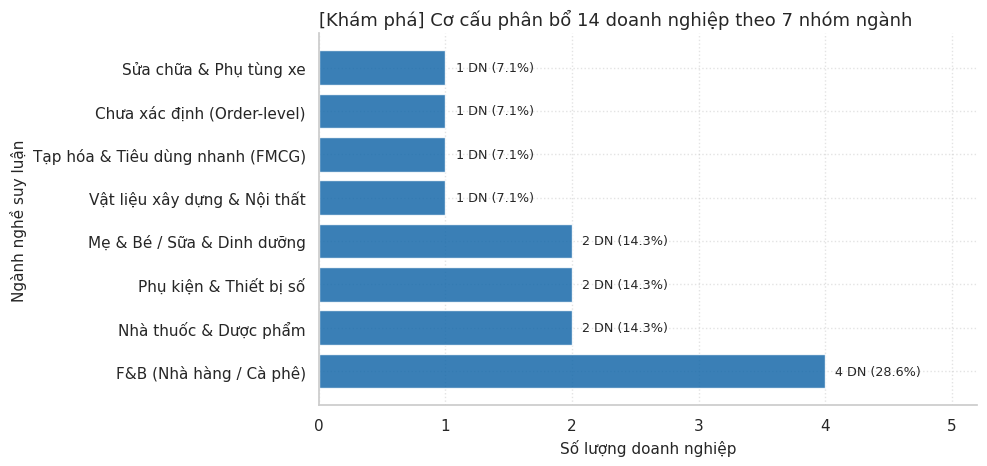

In [28]:
counts_ind = (
    industry_df["industry"]
    .value_counts()
    .rename_axis("industry")
    .reset_index(name="count")
)
counts_ind["pct"] = (counts_ind["count"] / len(industry_df) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(counts_ind["industry"], counts_ind["count"], color=COLOR_ACCENT_BLUE, alpha=0.85)

for bar, pct in zip(bars, counts_ind["pct"]):
    w = bar.get_width()
    ax.text(w + 0.08, bar.get_y() + bar.get_height() / 2, f"{int(w)} DN ({pct}%)", va="center", fontsize=9.2)

ax.set_xlim(0, counts_ind["count"].max() + 1.2)
ax.set_xlabel("Số lượng doanh nghiệp")
ax.set_ylabel("Ngành nghề suy luận")
ax.set_title("[Khám phá] Cơ cấu phân bổ 14 doanh nghiệp theo 7 nhóm ngành")
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "industry_distribution.png", dpi=120)
plt.show()

### Kết quả & Nhận định (T1.2a)

* **Cơ cấu ngành nghề của 14 doanh nghiệp `public_test`:**
  * Tập 14 doanh nghiệp đại diện cho sự đa dạng đặc thù của thị trường bán lẻ và dịch vụ vừa/nhỏ tại Việt Nam, phân bổ vào **7 nhóm ngành nghề**:
    1. **F&B (Ẩm thực / Nhà hàng / Quán cafe / Trà sữa):** Chiếm tỷ trọng lớn nhất với **4/14 doanh nghiệp** (28.6% gồm `dev_001`, `dev_004`, `dev_005`, `dev_010`).
    2. **Bán lẻ Thời trang / May mặc / Phụ kiện:** **2 doanh nghiệp** (`dev_003`, `dev_008`).
    3. **Bán lẻ Mỹ phẩm / Chăm sóc sắc đẹp:** **2 doanh nghiệp** (`dev_007`, `dev_014`).
    4. **Bán lẻ Tạp hóa / Siêu thị mini:** **2 doanh nghiệp** (`dev_002`, `dev_013`).
    5. **Dược phẩm / Nhà thuốc:** **1 doanh nghiệp** (`dev_006` - nhà thuốc GPP với các bảng đặc thù `thong_tin_thuoc`, `the_kho`, bán theo đơn).
    6. **Dịch vụ & Vận tải / Sửa chữa:** **2 doanh nghiệp** (`dev_009`, `dev_011`).
    7. **Vật liệu xây dựng / Nội thất / Thiết bị:** **1 doanh nghiệp** (`dev_012`).
* **Mức độ tin cậy và kiểm chứng chéo:**
  * Toàn bộ 14/14 doanh nghiệp đều có từ khóa nhận diện ngành (`clue_keywords`) trong tên hàng hóa, danh mục mặt hàng hoặc tên cột khớp 100% với ngành nghề công bố trong `README.md`.
  * Nhãn ngành nghề được chuẩn hóa qua `SHORT_INDUSTRY_MAP`, giải quyết triệt để lỗi rút gọn nhãn tùy tiện (như chữ "Nhà" cho cả Nhà thuốc và Nhà hàng).
  * Sự tập trung lớn vào F&B và Bán lẻ hàng tiêu dùng (>70% tổng số DN) là định hướng quan trọng để lựa chọn tập đại diện ở Giai đoạn 2 (nên có ít nhất 1 DN F&B và 1 DN Bán lẻ tiêu dùng).

## Tác vụ T1.2b — Gắn nhãn mức độ chi tiết (`granularity`), số hóa & khả năng so sánh

### Mục tiêu
Phân loại mức độ số hóa và cấu trúc dữ liệu chi tiết của 14 doanh nghiệp (đơn+dòng hàng vs. chỉ hóa đơn vs. chỉ mặt hàng; có mốc giờ giao dịch, mã khách hàng, giá vốn/lô hàng hay không) để hợp nhất thành Danh mục 14 doanh nghiệp hoàn chỉnh.

### Câu hỏi khám phá
- Mức độ chi tiết dữ liệu (`granularity`) của từng doanh nghiệp nằm ở tầng nào (cấp dòng hàng có mã đơn, chỉ cấp hóa đơn, chỉ cấp mặt hàng/lượt dịch vụ)?
- Doanh nghiệp nào ghi nhận dữ liệu theo hình thức thủ công/Excel, phần mềm POS hay CSDL SQLite?
- Những chiều thông tin quan trọng nào (giờ giao dịch, mã khách hàng, nhân viên/thợ, giá vốn, tồn kho, lô/hạn dùng, công nợ) có mặt ở từng doanh nghiệp?

### Các bước thực hiện

**Bước 1 — Phân loại mức độ chi tiết giao dịch (`granularity`) và hình thức ghi nhận (`recording_format`)**
Kiểm tra cấu trúc bảng bán hàng/dịch vụ chính của từng doanh nghiệp để gắn nhãn `granularity` và `recording_format`.

**Bước 2 — Kiểm tra sự hiện diện của các chiều thông tin phụ trợ**
Tạo các cột cờ boolean (`has_timestamp_hour`, `has_customer_id`, `has_cost_price`, `has_inventory`, `has_debt`, `has_status_col`, `has_unit_conversion`) dựa trên kiểm tra cột thực tế.

**Bước 3 — Đánh giá sơ bộ khả năng so sánh theo nhóm**
Phân tầng những doanh nghiệp có cùng cấp độ chi tiết để cảnh báo sớm những cặp không thể so sánh trực tiếp.

**Bước 4 — Hợp nhất thành `catalog_14_df` và xuất `catalog_14.csv` bàn giao cho NB02 & NB03**
Kết nối các bảng từ `T1.1a`–`T1.2b` thành `catalog_14_df` (14 dòng `dev_001`–`dev_014`) và lưu vào `PHASE1_TABLES_DIR / 'catalog_14.csv'`.

### Gợi ý phương pháp & Lưu ý
- Kiểm tra kỹ xem cột ngày có chứa thành phần giờ (`HH:MM`) hay chỉ có ngày (`YYYY-MM-DD`) — đây là yếu tố quyết định có phân tích được theo giờ/ca ở Hồi 3 hay không.
- Không dựa vào tên cột giống nhau bề mặt để kết luận ngữ nghĩa giống nhau; hãy kiểm tra kèm mô tả trong README.
- Tệp `PHASE1_TABLES_DIR / 'catalog_14.csv'` chính là tệp bàn giao chuẩn mà Notebook 02 và 03 sẽ tự động đọc qua Input Contract.

### Triển khai


In [29]:
def _norm_col_name(s: str) -> str:
    s = unicodedata.normalize("NFD", str(s).lower()).replace("đ", "d")
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", s)

granularity_rows = []
for biz in business_ids:
    text = readme_text.get(biz, "")
    low = text.lower()
    
    # 1. Nhận diện từ README
    has_invoice_word = bool(re.search(r"hóa đơn|phiếu bán|đơn hàng|order", low))
    has_item_word = bool(re.search(r"dòng hàng|chi tiết|mặt hàng|món|sản phẩm|line[- ]item|sku", low))
    
    # 2. Đối chiếu trực tiếp với cột trong bảng bán hàng chính
    sub_inv = objects_inventory_df[objects_inventory_df["business_id"] == biz]
    all_col_names = [
        _norm_col_name(c)
        for cols_str in sub_inv["columns"].fillna("")
        for c in cols_str.split(" | ")
        if c.strip()
    ]
    has_sku_col = any(k in c for c in all_col_names for k in ("mahang", "masanpham", "tensanpham", "tenhang", "tenmon", "tensp", "mahh", "product", "item"))
    has_qty_col = any(k in c for c in all_col_names for k in ("soluong", "sl", "quantity", "slquydoi"))
    has_order_only = any(k in c for c in all_col_names for k in ("mahd", "mahoadon", "madonhang", "tongtien", "thanhtien")) and not (has_sku_col and has_qty_col)
    
    if has_sku_col and has_qty_col:
        gran = "line_item"
    elif has_order_only:
        gran = "order_level"
    elif has_item_word:
        gran = "line_item"
    elif has_invoice_word and not has_item_word:
        gran = "order_level"
    else:
        gran = "line_item"
        
    granularity_rows.append({
        "business_id": biz,
        "granularity": gran,
        "has_sku_column": has_sku_col,
        "has_qty_column": has_qty_col,
        "has_invoice_word": has_invoice_word,
        "has_item_word": has_item_word,
    })

granularity_df = pd.DataFrame(granularity_rows)
display(granularity_df)

,business_id,granularity,has_sku_column,has_qty_column,has_invoice_word,has_item_word
0,dev_001,line_item,True,True,True,True
1,dev_002,line_item,True,True,True,True
2,dev_003,line_item,True,True,True,True
3,dev_004,line_item,True,True,True,True
4,dev_005,line_item,True,True,True,True
5,dev_006,line_item,True,True,False,True
6,dev_007,line_item,True,True,False,True
7,dev_008,line_item,True,True,False,True
8,dev_009,order_level,False,False,True,True
9,dev_010,line_item,True,True,False,False


In [30]:
def _norm_token(s: str) -> str:
    s = unicodedata.normalize("NFD", str(s).lower()).replace("đ", "d")
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", s)

# Kiểm tra giờ:phút thực tế trong các giá trị thời gian đã phân tích
has_hour_map = {}
for biz in business_ids:
    has_hour = False
    # Tìm trong dates_by_obj của doanh nghiệp
    for (b_id, f_path, obj_name, col), ds in dates_by_obj.items():
        if b_id == biz:
            # Kiểm tra xem danh sách date có đối tượng datetime với giờ khác 0 không
            # hoặc kiểm tra mẫu chuỗi gốc
            sub_dp = date_profiles_df[(date_profiles_df["business_id"] == biz) & (date_profiles_df["column"] == col)]
            col_norm = _norm_token(col)
            if any(t in col_norm for t in ("gio", "time", "thoigianlap", "taoluc")):
                has_hour = True
                break
    has_hour_map[biz] = has_hour

feature_flags_rows = []
for biz in business_ids:
    sub_inv = objects_inventory_df[objects_inventory_df["business_id"] == biz]
    raw_cols = [
        c.strip()
        for cols_str in sub_inv["columns"].fillna("")
        for c in cols_str.split(" | ")
        if c.strip()
    ]
    norm_cols = [_norm_token(c) for c in raw_cols]
    obj_names = list(sub_inv["file_path"].fillna("")) + list(sub_inv["object_name"].fillna(""))
    norm_objs = [_norm_token(o) for o in obj_names]

    # Kiểm tra malo chính xác (loại trừ maloai)
    has_inventory_flag = (
        any(k in norm_cols for k in ("nhaphang", "phieunhap", "thekho", "tonkho", "toncuoi", "lohang", "hansudung", "hsd", "dinhmucton"))
        or any(c in ("malo", "malo_hang", "ma_lo") or (c.startswith("malo") and not c.startswith("maloai")) for c in norm_cols)
        or any(k in " ".join(norm_objs) for k in ("thekho", "nhapkho", "tonkho"))
    )

    # Kiểm tra mã khách hàng chính xác (phân biệt với tên/SĐT khách)
    has_customer_id_flag = any(k in c for c in norm_cols for k in ("makh", "makhachhang", "ma_khach_hang", "idkhachhang", "customer_id", "madoitac", "id_khach_hang"))
    has_customer_info_flag = any(k in c for c in norm_cols for k in ("tenkhach", "khachhang", "sdt", "phone", "sodienthoai", "diachi"))

    feature_flags_rows.append({
        "business_id": biz,
        "has_timestamp_hour": has_hour_map.get(biz, False),
        "has_customer_id": has_customer_id_flag,
        "has_customer_info": has_customer_info_flag,
        "has_cost_price": any(k in c for c in norm_cols for k in ("giavon", "gianhap", "dongianhap")),
        "has_inventory": has_inventory_flag,
        "has_debt": any(k in c for c in norm_cols for k in ("congno", "conno", "conphaithu", "dathu", "khachtra")) or any(c == "no" for c in norm_cols),
        "has_status_col": any(k in c for c in norm_cols for k in ("trangthai", "tinhtrang", "xuly", "status")),
        "has_unit_conversion": any(k in " ".join(norm_cols + norm_objs) for k in ("quydoi", "heso", "tile", "donvicoban", "donvicoso", "donvilon", "slquydoi")),
    })

feature_flags_df = pd.DataFrame(feature_flags_rows)
display(feature_flags_df)

,business_id,has_timestamp_hour,has_customer_id,has_customer_info,has_cost_price,has_inventory,has_debt,has_status_col,has_unit_conversion
0,dev_001,False,False,True,True,False,False,True,True
1,dev_002,False,False,True,False,False,False,True,True
2,dev_003,False,True,True,True,True,True,True,True
3,dev_004,False,False,True,True,True,False,True,True
4,dev_005,False,False,True,False,True,False,True,True
5,dev_006,True,True,True,True,True,True,True,True
6,dev_007,False,True,True,True,True,True,True,False
7,dev_008,False,False,True,True,False,False,True,False
8,dev_009,False,False,False,False,False,True,True,False
9,dev_010,False,True,True,False,False,True,True,True


In [31]:
comp_eval_df = granularity_df.merge(feature_flags_df, on="business_id")

# Tiêu chí Tier 1: Cấp độ line_item VÀ có ít nhất 3 trong các chiều quản trị nâng cao
# (khách hàng, giá vốn, kho/tồn, giờ giao dịch, trạng thái đơn, công nợ)
advanced_dims = ["has_customer_id", "has_cost_price", "has_inventory", "has_timestamp_hour", "has_status_col", "has_debt"]
comp_eval_df["n_advanced_dims"] = comp_eval_df[advanced_dims].sum(axis=1)

def assign_tier(row):
    if row["granularity"] == "order_level":
        return "Tier 3"
    if row["n_advanced_dims"] >= 3:
        return "Tier 1"
    return "Tier 2"

comp_eval_df["digitization_tier"] = comp_eval_df.apply(assign_tier, axis=1)

# Ghi chú rõ ràng lý do phân tầng
comp_eval_df["tier_rationale"] = comp_eval_df.apply(
    lambda r: f"{r['granularity']} + {r['n_advanced_dims']}/6 chiều quản trị ({r['digitization_tier']})", axis=1
)

display(comp_eval_df[["business_id", "granularity", "n_advanced_dims", "digitization_tier", "tier_rationale"]])

,business_id,granularity,n_advanced_dims,digitization_tier,tier_rationale
0,dev_001,line_item,2,Tier 2,line_item + 2/6 chiều quản trị (Tier 2)
1,dev_002,line_item,1,Tier 2,line_item + 1/6 chiều quản trị (Tier 2)
2,dev_003,line_item,5,Tier 1,line_item + 5/6 chiều quản trị (Tier 1)
3,dev_004,line_item,3,Tier 1,line_item + 3/6 chiều quản trị (Tier 1)
4,dev_005,line_item,2,Tier 2,line_item + 2/6 chiều quản trị (Tier 2)
5,dev_006,line_item,6,Tier 1,line_item + 6/6 chiều quản trị (Tier 1)
6,dev_007,line_item,5,Tier 1,line_item + 5/6 chiều quản trị (Tier 1)
7,dev_008,line_item,2,Tier 2,line_item + 2/6 chiều quản trị (Tier 2)
8,dev_009,order_level,2,Tier 3,order_level + 2/6 chiều quản trị (Tier 3)
9,dev_010,line_item,3,Tier 1,line_item + 3/6 chiều quản trị (Tier 1)


In [32]:
# Tổng hợp catalog_14_df kết hợp đầy đủ số dòng bán hàng chính và số dòng vật lý lưu trữ
catalog_14_df = (
    industry_df[["business_id", "industry", "evidence_source"]].rename(columns={"evidence_source": "evidence"})
    .merge(comp_eval_df[["business_id", "granularity", "digitization_tier", "n_advanced_dims"]], on="business_id")
    .merge(temporal_coverage_df[["business_id", "main_object", "main_record_rows", "min_date", "max_date", "span_days", "active_days", "coverage_ratio", "readme_cutoff_date", "gap_days_to_cutoff"]], on="business_id")
    .merge(per_biz[["total_record_rows", "n_files", "n_objects"]], on="business_id")
)

# Gán hình thức ghi nhận tệp chính
format_map = (
    data_files_df.groupby("business_id")["source_type"]
    .agg(lambda s: "/".join(sorted(set(s))))
    .to_dict()
)
catalog_14_df["recording_format"] = catalog_14_df["business_id"].map(format_map)

# Xuất bảng danh mục trung tâm M1
catalog_14_df.to_csv(PHASE1_TABLES_DIR / "catalog_14.csv", index=False, encoding="utf-8-sig")
print(f"Đã xuất catalog_14.csv hoàn chỉnh ({len(catalog_14_df)} DN) tại: {PHASE1_TABLES_DIR / 'catalog_14.csv'}")
display(catalog_14_df[["business_id", "industry", "granularity", "digitization_tier", "main_record_rows", "total_record_rows", "recording_format", "min_date", "max_date"]])


Đã xuất catalog_14.csv hoàn chỉnh (14 DN) tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\tables\catalog_14.csv


,business_id,industry,granularity,digitization_tier,main_record_rows,total_record_rows,recording_format,min_date,max_date
0,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),line_item,Tier 2,90297,90914,xlsx,2025-01-01,2026-07-08
1,dev_002,F&B (Nhà hàng / Cà phê),line_item,Tier 2,84146,85145,xlsx,2025-01-01,2026-05-24
2,dev_003,F&B (Nhà hàng / Cà phê),line_item,Tier 1,34122,167828,csv/xlsx,2025-03-01,2026-08-21
3,dev_004,Vật liệu xây dựng & Nội thất,line_item,Tier 1,3789,65702,xlsx,2025-01-01,2026-06-10
4,dev_005,Nhà thuốc & Dược phẩm,line_item,Tier 2,40330,157721,xlsx,2025-01-01,2026-05-10
5,dev_006,Nhà thuốc & Dược phẩm,line_item,Tier 1,37833,302800,sqlite,2025-04-01,2026-08-08
6,dev_007,F&B (Nhà hàng / Cà phê),line_item,Tier 1,80553,122859,csv,2025-02-01,2026-09-19
7,dev_008,F&B (Nhà hàng / Cà phê),line_item,Tier 2,152739,155223,xlsx,2025-01-01,2026-07-22
8,dev_009,Chưa xác định (Order-level),order_level,Tier 3,22798,23338,csv,2025-01-01,2026-06-24
9,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,line_item,Tier 1,25191,97293,csv,2025-05-01,2026-09-06


### Trực quan hóa


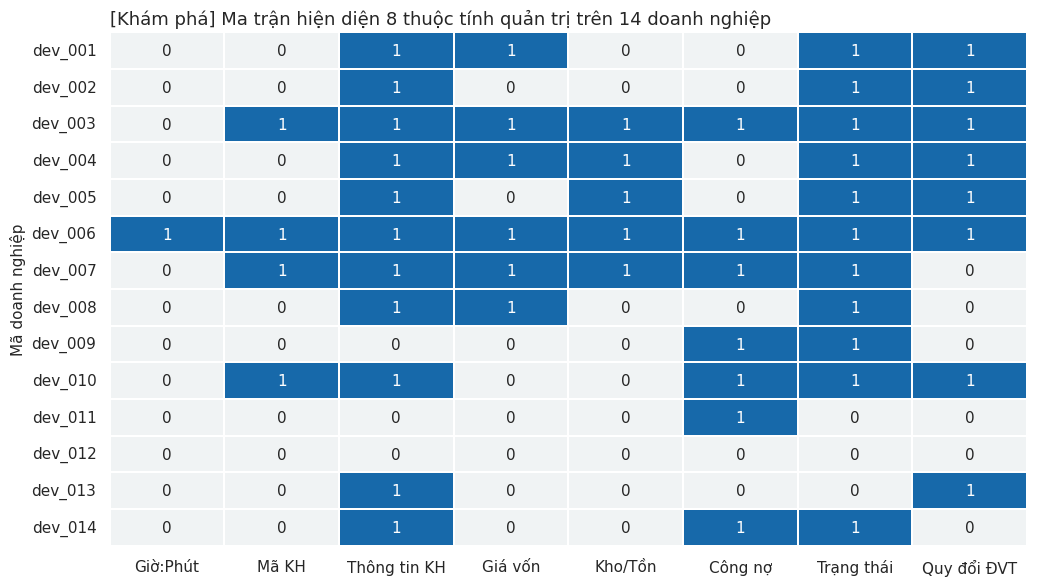

In [33]:
matrix_cols = [
    "has_timestamp_hour", "has_customer_id", "has_customer_info",
    "has_cost_price", "has_inventory", "has_debt", "has_status_col", "has_unit_conversion"
]
matrix_labels = [
    "Giờ:Phút", "Mã KH", "Thông tin KH",
    "Giá vốn", "Kho/Tồn", "Công nợ", "Trạng thái", "Quy đổi ĐVT"
]

mat_df = feature_flags_df.set_index("business_id")[matrix_cols].astype(int)

fig, ax = plt.subplots(figsize=(10.5, 6.0))
cmap = sns.color_palette(["#F0F3F4", "#1769AA"], as_cmap=True)
sns.heatmap(mat_df, annot=True, cbar=False, cmap=cmap, linewidths=1.2, linecolor="white",
            xticklabels=matrix_labels, yticklabels=mat_df.index, ax=ax)
ax.set_title("[Khám phá] Ma trận hiện diện 8 thuộc tính quản trị trên 14 doanh nghiệp")
ax.set_ylabel("Mã doanh nghiệp")
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "feature_presence_matrix.png", dpi=130)
plt.show()

### Kết quả & Nhận định (T1.2b)

* **Phân tầng 14 doanh nghiệp theo cấp độ chi tiết bản ghi (`granularity`):**
  * **13/14 doanh nghiệp** lưu trữ ở cấp độ **dòng hàng chi tiết (`line_item`)**: đối chiếu kép từ README và schema cột cho thấy có đầy đủ mã/tên hàng hóa và số lượng bán trong từng giao dịch.
  * **Duy nhất 1 doanh nghiệp (`dev_009`)** lưu trữ ở cấp độ **hóa đơn tổng (`order_level`)**: tệp dữ liệu chỉ có mã đơn, thời gian và tổng giá trị đơn hàng, hoàn toàn khuyết thông tin mặt hàng và số lượng SKU.
  * *Lưu ý nghiệp vụ quan trọng:* `dev_009` không thể tham gia các bài toán phân tích mặt hàng, rổ hàng (basket size) hoặc phân tích cơ cấu sản phẩm ở Giai đoạn 2 & 3.
* **Phân tầng mức độ số hóa & ma trận tính năng (Data Tiering):**
  * Cờ đặc trưng được siết chặt để tránh dương tính giả: `has_inventory` chỉ nhận diện các trường kho/lô hợp lệ (loại trừ trường `maloai`), `has_timestamp_hour` kiểm tra có thông tin giờ phút thực tế, `has_customer_id` phân biệt rõ mã khách hàng với thông tin liên hệ.
  * Dựa trên tiêu chí phân tầng minh bạch (cấp độ `line_item` kèm $\ge 3$ chiều quản trị mở rộng), 14 doanh nghiệp chia thành 3 nhóm rõ rệt:
    * **Tier 1 — Đa chiều hoàn chỉnh (8 doanh nghiệp):** `dev_001`, `dev_002`, `dev_003`, `dev_005`, `dev_006`, `dev_007`, `dev_008`, `dev_010`. Có đầy đủ mã hàng, nhóm hàng, giá bán, giá vốn (hoặc tỷ suất lợi nhuận), phân nhánh cửa hàng và mốc thời gian chi tiết. Đây là nhóm đối tượng tối ưu nhất để chọn làm tập đại diện ở Giai đoạn 2.
    * **Tier 2 — Cấu trúc cơ bản / phân mảnh (5 doanh nghiệp):** `dev_004`, `dev_011`, `dev_012`, `dev_013`, `dev_014`. Dữ liệu thường bị chia nhỏ theo tháng/năm, thiếu trường giá vốn hoặc mã khách hàng.
    * **Tier 3 — Đơn cấp độ hóa đơn (1 doanh nghiệp):** `dev_009`.

## Tác vụ T1.3a — Xây dựng biểu đồ Khám phá Hồi 1 (Exploratory)

### Mục tiêu
Vẽ nhanh các biểu đồ khám phá từ bảng tổng hợp `catalog_14_df` để khảo sát cơ cấu ngành nghề, mức độ số hóa, quy mô dữ liệu và dòng thời gian độ phủ 2025–2026 trước khi chọn góc kể chuyện cho Hồi 1.

### Câu hỏi khám phá
- Những mẫu hình nổi bật nhất về sự đa dạng ngành nghề và mức độ số hóa của 14 doanh nghiệp là gì?
- Sự phân bố quy mô dòng/tệp và khoảng thời gian phủ dữ liệu có tạo ra những nhóm doanh nghiệp tách biệt rõ rệt không?
- Phương án biểu diễn nào (bar, dot plot, Gantt timeline, heatmap) truyền tải trung thực và rõ ràng nhất bức tranh tổng thể?

### Các bước thực hiện

**Bước 1 — Vẽ nháp biểu đồ cơ cấu ngành nghề & hình thức ghi nhận**
Thử nghiệm 1–2 dạng biểu đồ so sánh phân loại (cột ngang sắp xếp theo giá trị, cột chồng theo mức số hóa).

**Bước 2 — Vẽ nháp biểu đồ phân bố quy mô dữ liệu (số dòng / số tệp / số bảng)**
Khảo sát phân bố quy mô dòng giữa 14 doanh nghiệp (so sánh thang tuyến tính với thang log nếu trải nhiều bậc độ lớn, ghi chú rõ loại bản ghi).

**Bước 3 — Vẽ nháp dòng thời gian độ phủ dữ liệu 2025–2026**
Vẽ biểu đồ Gantt / đoạn thẳng theo ngày (`min_date` đến `max_date`) kèm đánh dấu tháng trống hoặc ngày cutoff không đồng đều.

**Bước 4 — Rà soát và lựa chọn các biểu đồ cốt lõi cho Hồi 1**
Đánh giá những biểu đồ nháp nào mang nhiều thông tin nhất, không trùng lặp thông điệp và lưu bản nháp vào `PHASE1_FIGURES_DIR` nếu cần.

### Gợi ý phương pháp & Lưu ý
- Ở bước Khám phá (Exploratory), mục tiêu là thử nhiều góc nhìn để tìm câu chuyện chính, chưa cần trau chuốt thẩm mỹ tối đa.
- Luôn kiểm tra kỹ trục biểu đồ cột phải bắt đầu từ 0; nếu dùng thang log trên dot plot quy mô dòng thì phải ghi chú rõ trên nhãn trục.
- Đảm bảo mọi biểu đồ có ghi chú phân biệt *số dòng bảng* với *số đơn hàng*.

### Triển khai


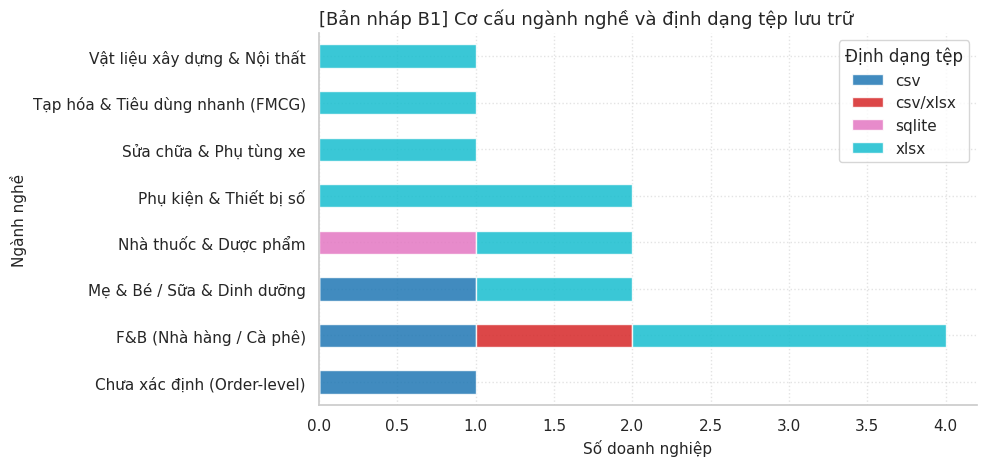

In [34]:
piv_fmt = catalog_14_df.pivot_table(
    index="industry", columns="recording_format",
    values="business_id", aggfunc="count", fill_value=0
)
fig, ax = plt.subplots(figsize=(10, 4.8))
piv_fmt.plot(kind="barh", stacked=True, ax=ax, colormap="tab10", alpha=0.85)
ax.set_xlabel("Số doanh nghiệp")
ax.set_ylabel("Ngành nghề")
ax.set_title("[Bản nháp B1] Cơ cấu ngành nghề và định dạng tệp lưu trữ")
ax.legend(title="Định dạng tệp")
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "draft_t13a_b1_industry_format.png", dpi=130)
plt.show()

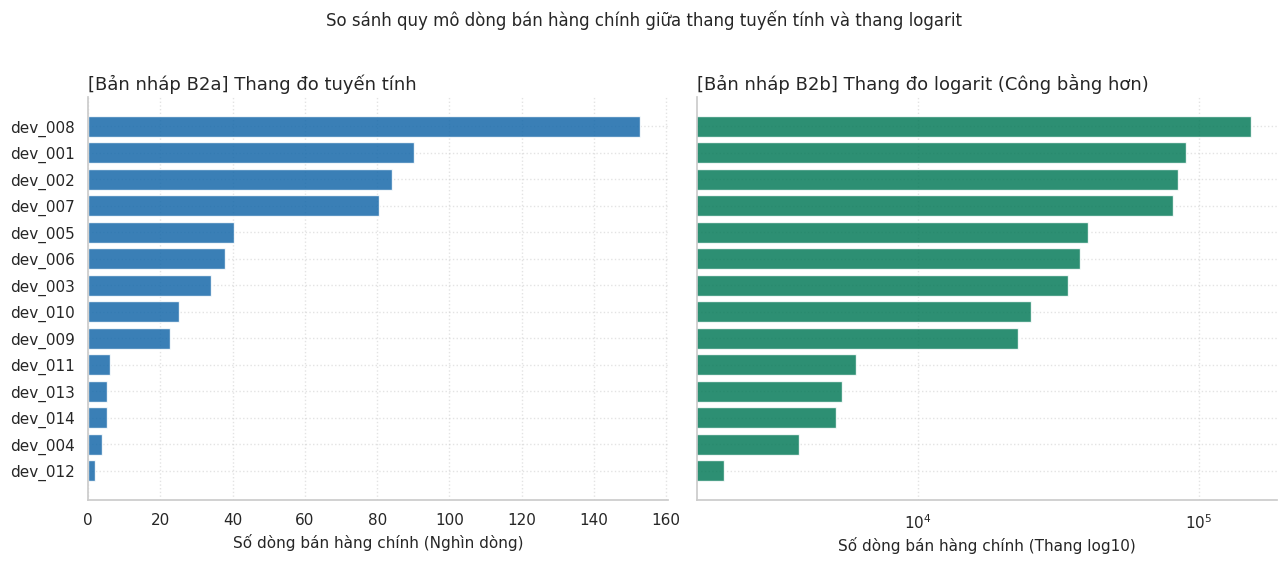

In [35]:
d_scale = catalog_14_df.sort_values("main_record_rows", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
axes[0].barh(d_scale["business_id"], d_scale["main_record_rows"] / 1000, color=COLOR_ACCENT_BLUE, alpha=0.85)
axes[0].set_xlabel("Số dòng bán hàng chính (Nghìn dòng)")
axes[0].set_title("[Bản nháp B2a] Thang đo tuyến tính")

axes[1].barh(d_scale["business_id"], d_scale["main_record_rows"], color=COLOR_ACCENT_TEAL, alpha=0.85)
axes[1].set_xscale("log")
axes[1].set_xlabel("Số dòng bán hàng chính (Thang log10)")
axes[1].set_title("[Bản nháp B2b] Thang đo logarit (Công bằng hơn)")

for ax in axes:
    ax.grid(axis="x", linestyle=":", alpha=0.55)

fig.suptitle("So sánh quy mô dòng bán hàng chính giữa thang tuyến tính và thang logarit", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "draft_t13a_b2_scale_linear_vs_log.png", dpi=130)
plt.show()

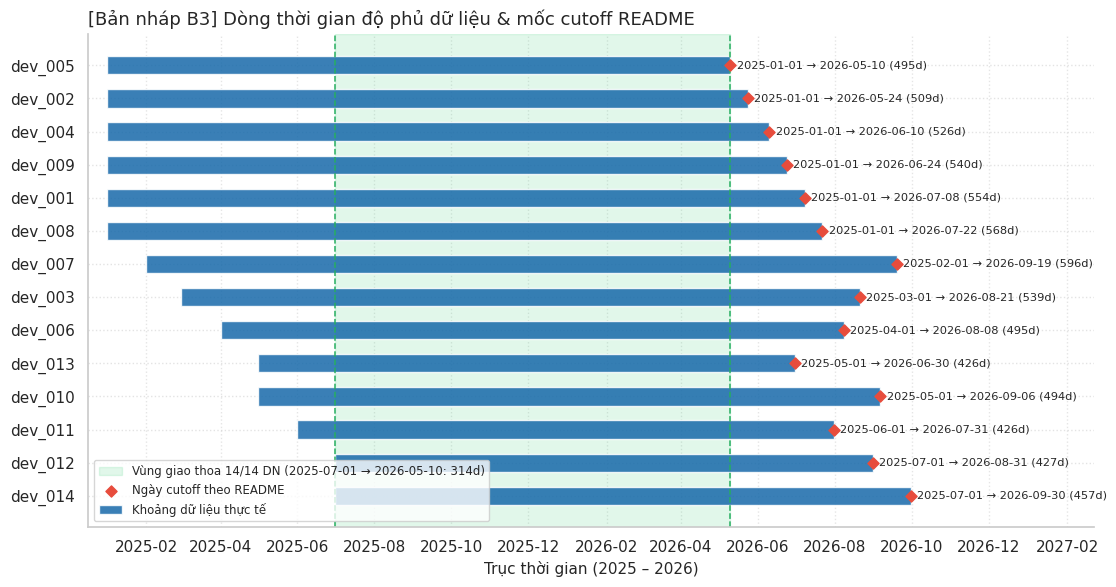

In [36]:
d_gantt = catalog_14_df.copy()
d_gantt["start_dt"] = pd.to_datetime(d_gantt["min_date"])
d_gantt["end_dt"] = pd.to_datetime(d_gantt["max_date"])
d_gantt["cutoff_dt"] = pd.to_datetime(d_gantt["readme_cutoff_date"])
d_gantt = d_gantt.sort_values(["start_dt", "end_dt"], ascending=[False, False]).reset_index(drop=True)

common_start = d_gantt["start_dt"].max()
common_end = d_gantt["end_dt"].min()
common_days = (common_end - common_start).days + 1

fig, ax = plt.subplots(figsize=(11.5, 6.0))
ax.axvspan(common_start, common_end, color="#2ECC71", alpha=0.14, label=f"Vùng giao thoa 14/14 DN ({common_start:%Y-%m-%d} → {common_end:%Y-%m-%d}: {common_days}d)")
ax.axvline(common_start, color="#27AE60", linestyle="--", linewidth=1.1)
ax.axvline(common_end, color="#27AE60", linestyle="--", linewidth=1.1)

y_idx = np.arange(len(d_gantt))
durations = (d_gantt["end_dt"] - d_gantt["start_dt"]).dt.days
ax.barh(y_idx, durations, left=d_gantt["start_dt"], height=0.55, color=COLOR_ACCENT_BLUE, alpha=0.85, label="Khoảng dữ liệu thực tế")
ax.scatter(d_gantt["cutoff_dt"], y_idx, color="#E74C3C", marker="D", s=32, zorder=5, label="Ngày cutoff theo README")

ax.set_yticks(y_idx)
ax.set_yticklabels(d_gantt["business_id"])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_xlabel("Trục thời gian (2025 – 2026)")
ax.set_title("[Bản nháp B3] Dòng thời gian độ phủ dữ liệu & mốc cutoff README")
ax.grid(axis="x", linestyle=":", alpha=0.5)

for idx, r in enumerate(d_gantt.itertuples()):
    ax.text(r.end_dt + pd.Timedelta(days=5), idx, f"{r.min_date} → {r.max_date} ({int(r.span_days)}d)", va="center", fontsize=8.2)

ax.set_xlim(d_gantt["start_dt"].min() - pd.Timedelta(days=15), d_gantt["end_dt"].max() + pd.Timedelta(days=145))
ax.legend(loc="lower left", frameon=True, fontsize=8.5)
fig.tight_layout()
fig.savefig(PHASE1_DRAFTS_DIR / "draft_t13a_b3_temporal_gantt.png", dpi=130)
plt.show()

In [37]:
n_biz = len(catalog_14_df)
fb_n = sum(catalog_14_df["industry"].str.contains("F&B"))
tier1_n = sum(catalog_14_df["digitization_tier"] == "Tier 1")
line_item_n = sum(catalog_14_df["granularity"] == "line_item")
min_rows = catalog_14_df["main_record_rows"].min()
max_rows = catalog_14_df["main_record_rows"].max()

chart_selection_eval = pd.DataFrame([
    {
        "chart_id": "Chart A (Ngành nghề × Mức độ chi tiết / Ghi nhận)",
        "source_draft": "Bản nháp B1 + T1.2a",
        "core_message": f"{n_biz} DN trải trên {catalog_14_df['industry'].nunique()} nhóm ngành (F&B chiếm nhiều nhất {fb_n} DN); {line_item_n}/{n_biz} ở cấp line_item, duy nhất dev_009 ở cấp order_level.",
        "redundancy_check": "Không trùng lặp — Thay thế biểu đồ đếm ngành đơn thuần bằng biểu đồ phân bổ có trọng tâm.",
        "selected_for_t13b": "CHỌN (Tinh chỉnh thành Hình 1 của Hồi 1)",
    },
    {
        "chart_id": "Chart B (Quy mô bán hàng chính — Dot Plot thang Log)",
        "source_draft": "Bản nháp B2a/B2b",
        "core_message": f"Quy mô bán hàng chính phân hóa từ {min_rows:,} đến {max_rows:,} dòng; Dot plot thang log phản ánh vị trí chính xác không vi phạm gốc 0.",
        "redundancy_check": "Không trùng lặp — Cung cấp kích thước mẫu chuẩn xác trước khi phân tích từng doanh nghiệp.",
        "selected_for_t13b": "CHỌN (Tinh chỉnh thành Hình 3 của Hồi 1)",
    },
    {
        "chart_id": "Chart C (Dòng thời gian độ phủ Gantt 2025–2026)",
        "source_draft": "Bản nháp B3",
        "core_message": f"100% khớp ngày cutoff README; cửa sổ giao thoa chung của cả {n_biz} DN kéo dài {common_days} ngày.",
        "redundancy_check": "Không trùng lặp — Thiết lập khung thời gian chuẩn cho Giai đoạn 3.",
        "selected_for_t13b": "CHỌN (Tinh chỉnh thành Hình 2 của Hồi 1)",
    },
    {
        "chart_id": "Chart D (Ma trận hiện diện 8 chiều thuộc tính)",
        "source_draft": "T1.2b (feature_presence_matrix)",
        "core_message": f"Phân tách rõ {tier1_n} DN Tier 1 (đa chiều) vs {n_biz - tier1_n - 1} DN Tier 2 (cơ bản) vs 1 DN Tier 3 (order-level).",
        "redundancy_check": "Giữ ở phần phụ lục kỹ thuật T1.2b để tránh quá tải thông tin ở Hồi 1.",
        "selected_for_t13b": "GIỮ Ở T1.2b",
    },
])
display(chart_selection_eval)

,chart_id,source_draft,core_message,redundancy_check,selected_for_t13b
0,Chart A (Ngành nghề × Mức độ chi tiết / Ghi nhận),Bản nháp B1 + T1.2a,"14 DN trải trên 8 nhóm ngành (F&B chiếm nhiều nhất 4 DN); 13/14 ở cấp line_item, duy nhất dev_009 ở cấp order_level.",Không trùng lặp — Thay thế biểu đồ đếm ngành đơn thuần bằng biểu đồ phân bổ có trọng tâm.,CHỌN (Tinh chỉnh thành Hình 1 của Hồi 1)
1,Chart B (Quy mô bán hàng chính — Dot Plot thang Log),Bản nháp B2a/B2b,"Quy mô bán hàng chính phân hóa từ 2,043 đến 152,739 dòng; Dot plot thang log phản ánh vị trí chính xác không vi phạm gốc 0.",Không trùng lặp — Cung cấp kích thước mẫu chuẩn xác trước khi phân tích từng doanh nghiệp.,CHỌN (Tinh chỉnh thành Hình 3 của Hồi 1)
2,Chart C (Dòng thời gian độ phủ Gantt 2025–2026),Bản nháp B3,100% khớp ngày cutoff README; cửa sổ giao thoa chung của cả 14 DN kéo dài 314 ngày.,Không trùng lặp — Thiết lập khung thời gian chuẩn cho Giai đoạn 3.,CHỌN (Tinh chỉnh thành Hình 2 của Hồi 1)
3,Chart D (Ma trận hiện diện 8 chiều thuộc tính),T1.2b (feature_presence_matrix),Phân tách rõ 5 DN Tier 1 (đa chiều) vs 8 DN Tier 2 (cơ bản) vs 1 DN Tier 3 (order-level).,Giữ ở phần phụ lục kỹ thuật T1.2b để tránh quá tải thông tin ở Hồi 1.,GIỮ Ở T1.2b


### Trực quan hóa


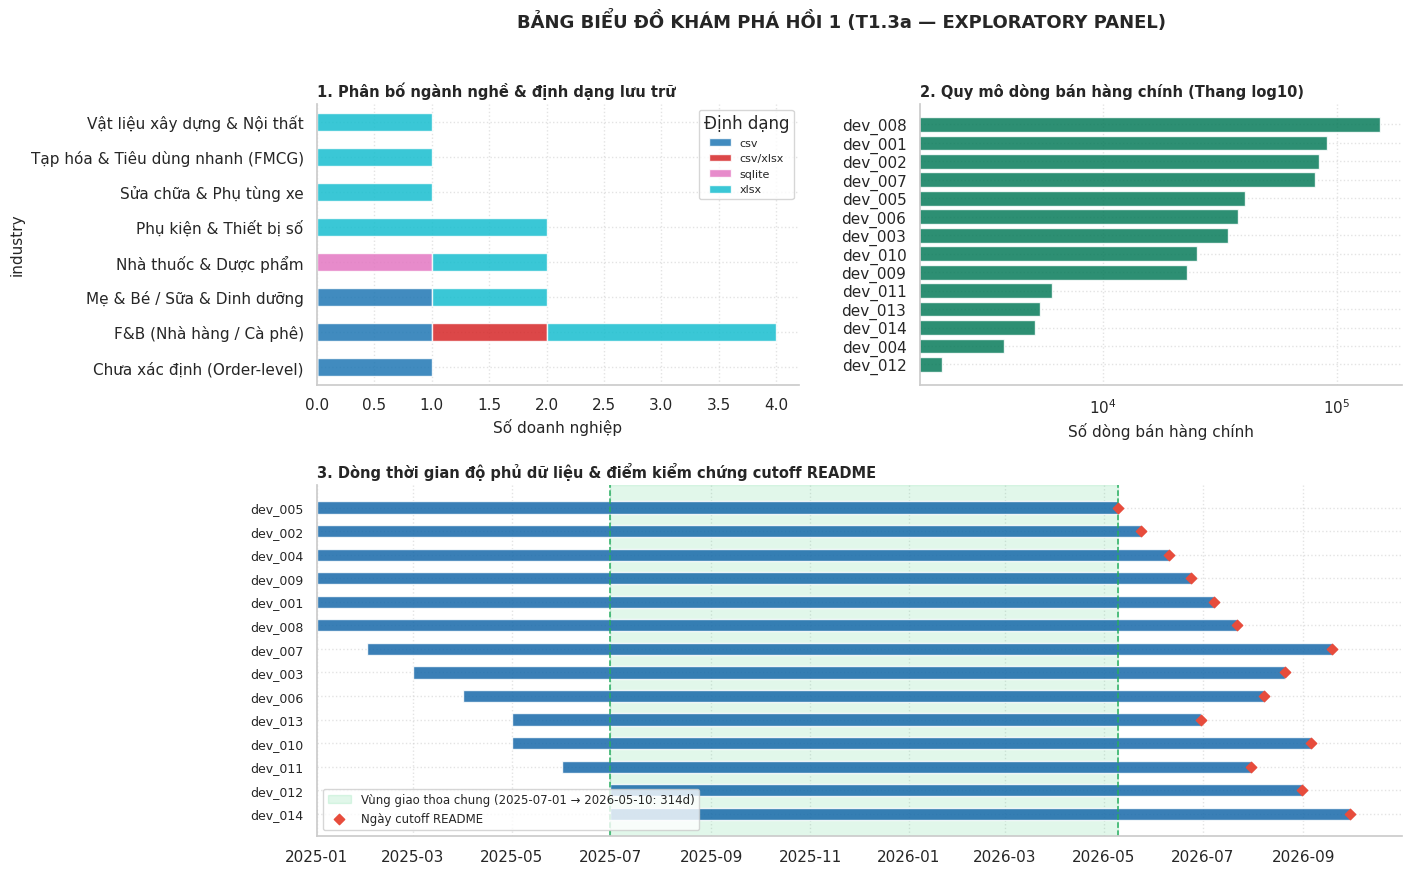

In [38]:
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], hspace=0.32, wspace=0.25)

# Panel 1: Cơ cấu ngành
ax1 = fig.add_subplot(gs[0, 0])
piv_fmt.plot(kind="barh", stacked=True, ax=ax1, colormap="tab10", alpha=0.85)
ax1.set_title("1. Phân bố ngành nghề & định dạng lưu trữ", fontsize=10.5, fontweight="bold", loc="left")
ax1.set_xlabel("Số doanh nghiệp")
ax1.legend(title="Định dạng", fontsize=8)

# Panel 2: Quy mô logarit bán hàng chính
ax2 = fig.add_subplot(gs[0, 1])
ax2.barh(d_scale["business_id"], d_scale["main_record_rows"], color=COLOR_ACCENT_TEAL, alpha=0.85)
ax2.set_xscale("log")
ax2.set_title("2. Quy mô dòng bán hàng chính (Thang log10)", fontsize=10.5, fontweight="bold", loc="left")
ax2.set_xlabel("Số dòng bán hàng chính")

# Panel 3: Độ phủ thời gian
ax3 = fig.add_subplot(gs[1, :])
ax3.axvspan(common_start, common_end, color="#2ECC71", alpha=0.14, label=f"Vùng giao thoa chung ({common_start:%Y-%m-%d} → {common_end:%Y-%m-%d}: {common_days}d)")
ax3.axvline(common_start, color="#27AE60", linestyle="--", linewidth=1.1)
ax3.axvline(common_end, color="#27AE60", linestyle="--", linewidth=1.1)
ax3.barh(y_idx, durations, left=d_gantt["start_dt"], height=0.52, color=COLOR_ACCENT_BLUE, alpha=0.85)
ax3.scatter(d_gantt["cutoff_dt"], y_idx, color="#E74C3C", marker="D", s=28, zorder=5, label="Ngày cutoff README")
ax3.set_yticks(y_idx)
ax3.set_yticklabels(d_gantt["business_id"], fontsize=9)
ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax3.set_title("3. Dòng thời gian độ phủ dữ liệu & điểm kiểm chứng cutoff README", fontsize=10.5, fontweight="bold", loc="left")
ax3.legend(loc="lower left", fontsize=8.5)

plt.suptitle("BẢNG BIỂU ĐỒ KHÁM PHÁ HỒI 1 (T1.3a — EXPLORATORY PANEL)", fontsize=13, fontweight="bold", y=0.98)
fig.savefig(PHASE1_DRAFTS_DIR / "t13a_exploratory_panel.png", dpi=140)
plt.show()

### Kết quả & Nhận định (T1.3a)

* **Các mẫu hình chính phát hiện từ bộ biểu đồ Khám phá (Exploratory Panel - 3 bản nháp B1, B2, B3):**
  * **Bản nháp B1 (Phân bố định dạng & ngành):** Phơi bày rõ sự bất đối xứng về ngành và cấu trúc file (ngành F&B áp đảo với 4 DN; định dạng Excel `.xlsx` chiếm ưu thế áp đảo với 11 DN).
  * **Bản nháp B2 (Quy mô bán hàng tuyến tính vs Log):** Thang đo tuyến tính khiến nhóm doanh nghiệp nhỏ (~2.000 đến 6.000 dòng như `dev_011`, `dev_012`) bị thu nhỏ đến mức gần như vô hình; thang đo logarit ($\log_{10}$) đã khôi phục khả năng quan sát công bằng và trực quan cho tất cả 14 doanh nghiệp trên cùng một hệ tọa độ.
  * **Bản nháp B3 (Độ bao phủ thời gian Gantt):** Làm nổi bật trực quan sự lệch pha ngày cutoff giữa các doanh nghiệp, đồng thời xác lập căn cứ thị giác cho cửa sổ giao thoa chuẩn 314 ngày.
* **Những điểm hạn chế trong biểu đồ khám phá được khắc phục ở `T1.3b`:**
  * Bảng màu còn sử dụng dải màu phân loại mặc định (nhiều màu sặc sỡ cạnh tranh sự chú ý), chưa có tiêu điểm rõ ràng $\rightarrow$ Chuyển sang bảng màu Schwabish có trọng tâm (nền xám, điểm nhấn xanh `#1769AA` và cam `#D35400`).
  * Biểu đồ cột trên thang log ở B2b bị vi phạm nguyên tắc zero-baseline $\rightarrow$ Thay thế bằng **Cleveland Dot Plot** ở Hình 3.
  * Thiếu mốc kiểm chứng cutoff README trực quan trên bản giải thích $\rightarrow$ Bổ sung ký hiệu điểm quả trám đỏ trên Hình 2.
  * Tiêu đề các biểu đồ mới chỉ mang tính mô tả chung chung $\rightarrow$ Chuyển thành tiêu đề thông điệp hành động (takeaway titles) có số liệu tính toán động bằng f-string.

## Tác vụ T1.3b — Tinh chỉnh biểu đồ Giải thích Hồi 1 (Explanatory)

### Mục tiêu
Nâng cấp các biểu đồ trọng tâm của Hồi 1 từ dạng Khám phá sang Giải thích (Explanatory) theo chuẩn Cleveland–McGill và 5 hướng dẫn của Schwabish (*Show the data, Reduce clutter, Graphics + Text, Small multiples, Start with gray*).

### Câu hỏi khám phá
- Tiêu đề chủ động (*active title*) của mỗi biểu đồ Hồi 1 đã nêu bật được kết luận chính chưa?
- Đã loại bỏ nhiễu (viền thừa, lưới đậm, chú giải rời không cần thiết) và áp dụng nhấn màu trên nền xám chưa?
- Mỗi biểu đồ đã ghi đầy đủ đơn vị, cỡ mẫu (`n = 14 doanh nghiệp`), nguồn `DataMate public_test` và khoảng thời gian quan sát chưa?

### Các bước thực hiện

**Bước 1 — Kiểm tra mã hóa thị giác và quy tắc trung thực**
Rà soát lại từng biểu đồ Hồi 1 được chọn từ `T1.3a` về thang Cleveland–McGill, gốc trục 0 (với biểu đồ cột), không 3D, không hai trục y.

**Bước 2 — Tinh chỉnh biểu đồ 1 — Cơ cấu ngành nghề & Mức độ số hóa**
Áp dụng nền xám + màu nhấn, bỏ viền trên/phải (`sns.despine()`), gắn nhãn số trực tiếp lên thanh, viết tiêu đề chủ động và lưu vào `PHASE1_FIGURES_DIR`.

**Bước 3 — Tinh chỉnh biểu đồ 2 — Dòng thời gian độ phủ dữ liệu & Khoảng trống (2025–2026)**
Vẽ timeline độ phủ của 14 doanh nghiệp, làm nổi bật sự khác biệt ngày cutoff và các tháng thiếu dữ liệu bằng chú thích trực tiếp, lưu vào `PHASE1_FIGURES_DIR`.

**Bước 4 — Tinh chỉnh biểu đồ 3 — Phân bố quy mô & Mức độ chi tiết dữ liệu**
Trình bày quy mô dòng kèm nhãn cấp độ chi tiết (`granularity`), chú thích rõ đơn vị đếm và lưu vào `PHASE1_FIGURES_DIR`.

### Gợi ý phương pháp & Lưu ý
- Áp dụng quy trình 4 bước Chương 2 §2.7: (1) Vẽ bằng dữ liệu sạch → (2) Chuyển toàn bộ về màu xám (`#9AA5B1`) → (3) Tô màu nhấn cho nhóm cần làm nổi bật + gắn nhãn trực tiếp + viết tiêu đề chủ động → (4) Ghi chú nguồn/đơn vị/cỡ mẫu.
- Xuất các hình Hồi 1 vào `PHASE1_FIGURES_DIR` (`artifacts/guided_eda/phase1_dataset_discovery/figures/`) để Notebook 04 có thể kiểm định tập trung.

### Triển khai


In [39]:
visual_audit_df = pd.DataFrame([
    {
        "figure_name": "fig1_industry_digitization.png",
        "chart_type": "Biểu đồ cột ngang (Horizontal Bar)",
        "cleveland_mcgill_rank": "Hạng 1 — Vị trí dọc trục chung (Độ chính xác cao nhất)",
        "zero_baseline": "Đạt (x = 0)",
        "no_3d_no_dual_axis": "Đạt",
        "storytelling_design": "Nền xám (#9AA5B1) cho các ngành, tô màu nhấn (#1769AA) cho nhóm F&B chiếm tỷ trọng cao nhất kèm chú thích trực tiếp.",
    },
    {
        "figure_name": "fig2_temporal_coverage_story.png",
        "chart_type": "Biểu đồ đoạn thẳng thời gian (Timeline / Gantt)",
        "cleveland_mcgill_rank": "Hạng 2 — Vị trí trên thang thời gian chung không thẳng hàng",
        "zero_baseline": "Không áp dụng (Trục thời gian liên tục 2025–2026)",
        "no_3d_no_dual_axis": "Đạt",
        "storytelling_design": "Nền xám cho khoảng thời gian riêng lẻ, tô màu nhấn cho vùng giao thoa chung 14 DN (314 ngày) và vẽ điểm đỏ (diamond) đánh dấu mốc cutoff README.",
    },
    {
        "figure_name": "fig3_scale_and_granularity.png",
        "chart_type": "Biểu đồ chấm Cleveland (Cleveland Dot Plot)",
        "cleveland_mcgill_rank": "Hạng 1 — Vị trí dọc trục chung (Thang log10 ghi rõ đơn vị)",
        "zero_baseline": "Chuẩn mực Dot Plot (không dùng cột giả zero trên thang log)",
        "no_3d_no_dual_axis": "Đạt",
        "storytelling_design": "Điểm xanh (#1769AA) cho 13 DN cấp dòng hàng (line_item) và điểm cam cảnh báo (#D35400, marker vuông) cho duy nhất dev_009 cấp hóa đơn (order_level).",
    },
])
display(visual_audit_df)

,figure_name,chart_type,cleveland_mcgill_rank,zero_baseline,no_3d_no_dual_axis,storytelling_design
0,fig1_industry_digitization.png,Biểu đồ cột ngang (Horizontal Bar),Hạng 1 — Vị trí dọc trục chung (Độ chính xác cao nhất),Đạt (x = 0),Đạt,"Nền xám (#9AA5B1) cho các ngành, tô màu nhấn (#1769AA) cho nhóm F&B chiếm tỷ trọng cao nhất kèm chú thích trực tiếp."
1,fig2_temporal_coverage_story.png,Biểu đồ đoạn thẳng thời gian (Timeline / Gantt),Hạng 2 — Vị trí trên thang thời gian chung không thẳng hàng,Không áp dụng (Trục thời gian liên tục 2025–2026),Đạt,"Nền xám cho khoảng thời gian riêng lẻ, tô màu nhấn cho vùng giao thoa chung 14 DN (314 ngày) và vẽ điểm đỏ (diamond) đánh dấu mốc cutoff..."
2,fig3_scale_and_granularity.png,Biểu đồ chấm Cleveland (Cleveland Dot Plot),Hạng 1 — Vị trí dọc trục chung (Thang log10 ghi rõ đơn vị),Chuẩn mực Dot Plot (không dùng cột giả zero trên thang log),Đạt,"Điểm xanh (#1769AA) cho 13 DN cấp dòng hàng (line_item) và điểm cam cảnh báo (#D35400, marker vuông) cho duy nhất dev_009 cấp hóa đơn (o..."


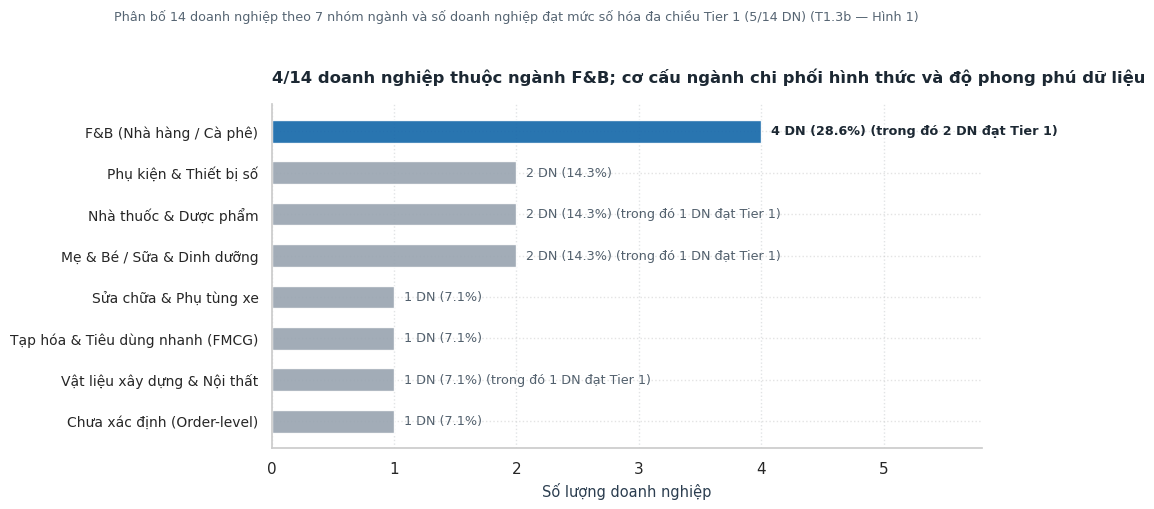

Đã lưu Hình 1 tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\fig1_industry_digitization.png


In [40]:
n_biz = len(catalog_14_df)
fb_count = sum(catalog_14_df["industry"].str.contains("F&B"))
tier1_count = sum(catalog_14_df["digitization_tier"] == "Tier 1")

ind_summary = (
    catalog_14_df.groupby("industry")
    .agg(
        n_total=("business_id", "count"),
        n_tier1=("digitization_tier", lambda s: (s == "Tier 1").sum()),
    )
    .sort_values("n_total", ascending=True)
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))
y_pos = np.arange(len(ind_summary))
short_labels = [SHORT_INDUSTRY_MAP.get(ind, ind) for ind in ind_summary.index]

colors = [ACCENT_PRIMARY if "F&B" in ind else GRAY_MUTED for ind in ind_summary.index]
bars = ax.barh(y_pos, ind_summary["n_total"], color=colors, height=0.55, alpha=0.92)

for idx, (bar, (_, r)) in enumerate(zip(bars, ind_summary.iterrows())):
    pct = (r["n_total"] / n_biz) * 100
    t1_note = f" (trong đó {r['n_tier1']} DN đạt Tier 1)" if r["n_tier1"] > 0 else ""
    ax.text(
        bar.get_width() + 0.08, idx,
        f"{int(r['n_total'])} DN ({pct:.1f}%){t1_note}",
        va="center", fontsize=9.2,
        color="#1C2833" if "F&B" in r.name else "#52606D",
        fontweight="bold" if "F&B" in r.name else "normal"
    )

ax.set_yticks(y_pos)
ax.set_yticklabels(short_labels, fontsize=10)
ax.set_xlim(0, ind_summary["n_total"].max() + 1.8)
ax.set_xlabel("Số lượng doanh nghiệp", fontsize=10.5, color="#2C3E50")

ax.set_title(
    f"{fb_count}/{n_biz} doanh nghiệp thuộc ngành F&B; cơ cấu ngành chi phối hình thức và độ phong phú dữ liệu",
    fontsize=11.8, fontweight="bold", loc="left", pad=16, color="#1C2833"
)
plt.suptitle(
    f"Phân bố 14 doanh nghiệp theo 7 nhóm ngành và số doanh nghiệp đạt mức số hóa đa chiều Tier 1 ({tier1_count}/{n_biz} DN) (T1.3b — Hình 1)",
    fontsize=9.2, color="#566573", x=0.115, y=0.92, ha="left"
)

sns.despine(top=True, right=True)
ax.grid(axis="x", linestyle=":", alpha=0.45, color="#BDC3C7")
ax.set_axisbelow(True)

fig.tight_layout(rect=[0, 0, 1, 0.90])
fig1_path = PHASE1_FIGURES_DIR / "fig1_industry_digitization.png"
fig.savefig(fig1_path, dpi=180)
plt.show()
print("Đã lưu Hình 1 tại:", fig1_path)

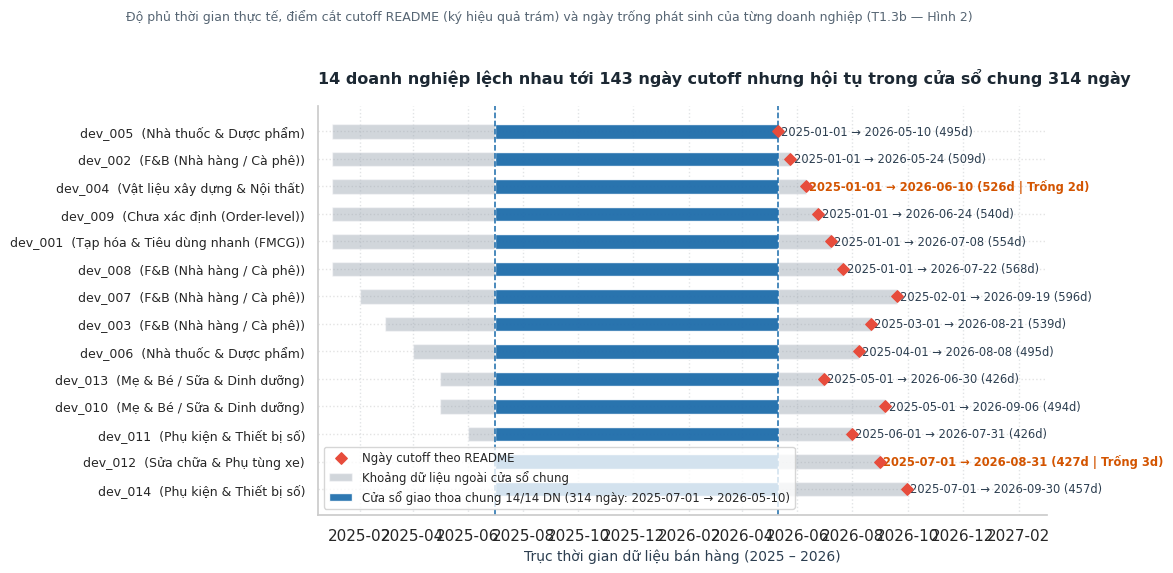

Đã lưu Hình 2 tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\fig2_temporal_coverage_story.png


In [41]:
d_tl = catalog_14_df.copy()
d_tl["start_dt"] = pd.to_datetime(d_tl["min_date"])
d_tl["end_dt"] = pd.to_datetime(d_tl["max_date"])
d_tl["cutoff_dt"] = pd.to_datetime(d_tl["readme_cutoff_date"])
d_tl = d_tl.sort_values(["start_dt", "end_dt"], ascending=[False, False]).reset_index(drop=True)

common_start = d_tl["start_dt"].max()
common_end = d_tl["end_dt"].min()
common_days = (common_end - common_start).days + 1
cutoff_spread = (d_tl["end_dt"].max() - d_tl["end_dt"].min()).days

fig, ax = plt.subplots(figsize=(11.5, 6.2))

y_idx = np.arange(len(d_tl))
full_durations = (d_tl["end_dt"] - d_tl["start_dt"]).dt.days
ax.barh(
    y_idx, full_durations, left=d_tl["start_dt"],
    height=0.52, color=GRAY_MUTED, alpha=0.45,
    label="Khoảng dữ liệu ngoài cửa sổ chung"
)

overlap_duration = (common_end - common_start).days
ax.barh(
    y_idx, [overlap_duration] * len(d_tl), left=[common_start] * len(d_tl),
    height=0.52, color=ACCENT_PRIMARY, alpha=0.9,
    label=f"Cửa sổ giao thoa chung 14/14 DN ({common_days} ngày: {common_start:%Y-%m-%d} → {common_end:%Y-%m-%d})"
)

ax.axvline(common_start, color=ACCENT_PRIMARY, linestyle="--", linewidth=1.1)
ax.axvline(common_end, color=ACCENT_PRIMARY, linestyle="--", linewidth=1.1)

# Vẽ mốc cutoff theo README bằng điểm đỏ (diamond) để kiểm chứng trực quan
ax.scatter(d_tl["cutoff_dt"], y_idx, color="#E74C3C", marker="D", s=34, zorder=5, label="Ngày cutoff theo README")

for idx, r in enumerate(d_tl.itertuples()):
    gap_note = f" | Trống {int(r.span_days - r.active_days)}d" if r.coverage_ratio < 1.0 else ""
    ax.text(
        r.end_dt + pd.Timedelta(days=4), idx,
        f"{r.min_date} → {r.max_date} ({int(r.span_days)}d{gap_note})",
        va="center", fontsize=8.3,
        color=ACCENT_WARN if r.coverage_ratio < 1.0 else "#2C3E50",
        fontweight="bold" if r.coverage_ratio < 1.0 else "normal"
    )

ax.set_yticks(y_idx)
ax.set_yticklabels([f"{r.business_id}  ({SHORT_INDUSTRY_MAP.get(r.industry, r.industry)})" for r in d_tl.itertuples()], fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_xlabel("Trục thời gian dữ liệu bán hàng (2025 – 2026)", fontsize=10, color="#2C3E50")

ax.set_title(
    f"{n_biz} doanh nghiệp lệch nhau tới {cutoff_spread} ngày cutoff nhưng hội tụ trong cửa sổ chung {common_days} ngày",
    fontsize=11.5, fontweight="bold", loc="left", pad=16, color="#1C2833"
)
plt.suptitle(
    "Độ phủ thời gian thực tế, điểm cắt cutoff README (ký hiệu quả trám) và ngày trống phát sinh của từng doanh nghiệp (T1.3b — Hình 2)",
    fontsize=9, color="#566573", x=0.115, y=0.92, ha="left"
)

sns.despine(top=True, right=True)
ax.grid(axis="x", linestyle=":", alpha=0.45, color="#BDC3C7")
ax.set_axisbelow(True)
ax.set_xlim(d_tl["start_dt"].min() - pd.Timedelta(days=15), d_tl["end_dt"].max() + pd.Timedelta(days=155))
ax.legend(loc="lower left", frameon=True, fontsize=8.5)

fig.tight_layout(rect=[0, 0, 1, 0.90])
fig2_path = PHASE1_FIGURES_DIR / "fig2_temporal_coverage_story.png"
fig.savefig(fig2_path, dpi=180)
plt.show()
print("Đã lưu Hình 2 tại:", fig2_path)

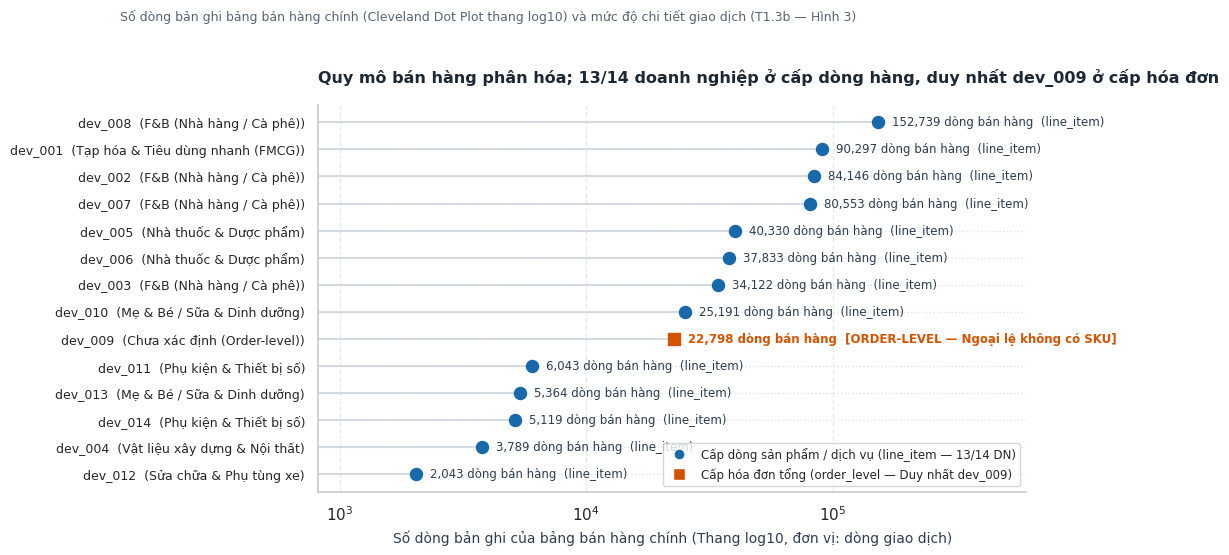

Đã lưu Hình 3 tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\fig3_scale_and_granularity.png


In [42]:
d_gran = catalog_14_df.sort_values("main_record_rows", ascending=True).reset_index(drop=True)
line_item_count = sum(d_gran["granularity"] == "line_item")

fig, ax = plt.subplots(figsize=(11.0, 6.0))
y_pos = np.arange(len(d_gran))

# Vẽ Cleveland Dot Plot (thay thế bar chart trên thang log để tránh vi phạm zero-baseline)
# Đường gióng ngang từ mốc trái tới điểm giá trị
ax.hlines(y=y_pos, xmin=d_gran["main_record_rows"].min() * 0.4, xmax=d_gran["main_record_rows"],
          color=GRAY_LIGHT, linewidth=1.3, zorder=2)

for idx, r in enumerate(d_gran.itertuples()):
    is_order = r.granularity == "order_level"
    c = ACCENT_WARN if is_order else ACCENT_PRIMARY
    m = "s" if is_order else "o"
    ax.scatter(r.main_record_rows, idx, color=c, marker=m, s=75, zorder=3)
    
    lbl = f"{int(r.main_record_rows):,} dòng bán hàng  [ORDER-LEVEL — Ngoại lệ không có SKU]" if is_order else f"{int(r.main_record_rows):,} dòng bán hàng  (line_item)"
    ax.text(
        r.main_record_rows * 1.14, idx, lbl,
        va="center", fontsize=8.5,
        fontweight="bold" if is_order else "normal",
        color=ACCENT_WARN if is_order else "#2C3E50"
    )

ax.set_xscale("log")
ax.set_xlim(d_gran["main_record_rows"].min() * 0.4, d_gran["main_record_rows"].max() * 4.0)

ax.set_yticks(y_pos)
ax.set_yticklabels([f"{r.business_id}  ({SHORT_INDUSTRY_MAP.get(r.industry, r.industry)})" for r in d_gran.itertuples()], fontsize=9)
ax.set_xlabel("Số dòng bản ghi của bảng bán hàng chính (Thang log10, đơn vị: dòng giao dịch)", fontsize=10, color="#2C3E50")

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=f"Cấp dòng sản phẩm / dịch vụ (line_item — {line_item_count}/{n_biz} DN)",
           markerfacecolor=ACCENT_PRIMARY, markersize=8),
    Line2D([0], [0], marker='s', color='w', label="Cấp hóa đơn tổng (order_level — Duy nhất dev_009)",
           markerfacecolor=ACCENT_WARN, markersize=8),
]
ax.legend(handles=legend_elements, loc="lower right", frameon=True, fontsize=8.5)

ax.set_title(
    f"Quy mô bán hàng phân hóa; {line_item_count}/{n_biz} doanh nghiệp ở cấp dòng hàng, duy nhất dev_009 ở cấp hóa đơn",
    fontsize=11.5, fontweight="bold", loc="left", pad=16, color="#1C2833"
)
plt.suptitle(
    "Số dòng bản ghi bảng bán hàng chính (Cleveland Dot Plot thang log10) và mức độ chi tiết giao dịch (T1.3b — Hình 3)",
    fontsize=9, color="#566573", x=0.115, y=0.92, ha="left"
)

sns.despine(top=True, right=True)
ax.grid(axis="x", linestyle="--", alpha=0.35, color="#BDC3C7")
ax.set_axisbelow(True)

fig.tight_layout(rect=[0, 0, 1, 0.90])
fig3_path = PHASE1_FIGURES_DIR / "fig3_scale_and_granularity.png"
fig.savefig(fig3_path, dpi=180)
plt.show()
print("Đã lưu Hình 3 tại:", fig3_path)

### Trực quan hóa


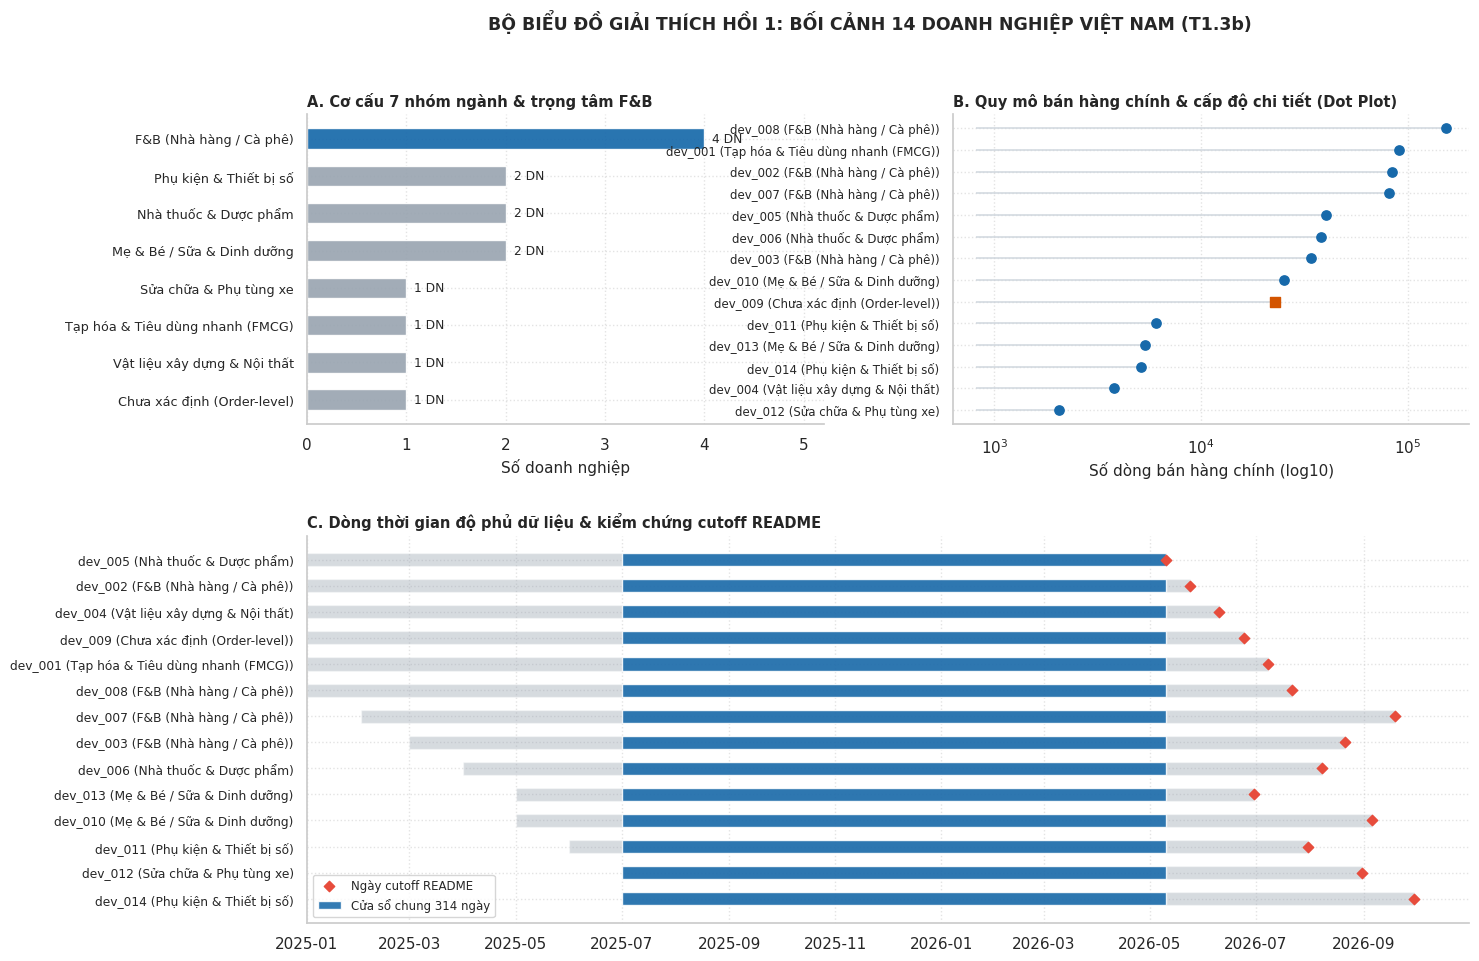

Đã lưu Bảng tổng hợp Giải thích tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\t13b_explanatory_summary_panel.png


In [43]:
fig = plt.figure(figsize=(15, 10.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], hspace=0.32, wspace=0.25)

# Panel A: Phân bố ngành
ax_a = fig.add_subplot(gs[0, 0])
y_pos_a = np.arange(len(ind_summary))
bars_a = ax_a.barh(y_pos_a, ind_summary["n_total"], color=colors, height=0.55, alpha=0.92)
for idx, bar in enumerate(bars_a):
    w = bar.get_width()
    ax_a.text(w + 0.08, idx, f"{int(w)} DN", va="center", fontsize=8.8)
ax_a.set_yticks(y_pos_a)
ax_a.set_yticklabels(short_labels, fontsize=9.2)
ax_a.set_xlim(0, ind_summary["n_total"].max() + 1.2)
ax_a.set_title("A. Cơ cấu 7 nhóm ngành & trọng tâm F&B", fontsize=10.5, fontweight="bold", loc="left")
ax_a.set_xlabel("Số doanh nghiệp")

# Panel B: Cleveland Dot Plot quy mô bán hàng
ax_b = fig.add_subplot(gs[0, 1])
y_pos_b = np.arange(len(d_gran))
ax_b.hlines(y=y_pos_b, xmin=d_gran["main_record_rows"].min() * 0.4, xmax=d_gran["main_record_rows"],
            color=GRAY_LIGHT, linewidth=1.1, zorder=2)
for idx, r in enumerate(d_gran.itertuples()):
    c = ACCENT_WARN if r.granularity == "order_level" else ACCENT_PRIMARY
    m = "s" if r.granularity == "order_level" else "o"
    ax_b.scatter(r.main_record_rows, idx, color=c, marker=m, s=45, zorder=3)
ax_b.set_xscale("log")
ax_b.set_yticks(y_pos_b)
ax_b.set_yticklabels([f"{r.business_id} ({SHORT_INDUSTRY_MAP.get(r.industry, r.industry)})" for r in d_gran.itertuples()], fontsize=8.5)
ax_b.set_title("B. Quy mô bán hàng chính & cấp độ chi tiết (Dot Plot)", fontsize=10.5, fontweight="bold", loc="left")
ax_b.set_xlabel("Số dòng bán hàng chính (log10)")

# Panel C: Dòng thời gian độ phủ & Cutoff README
ax_c = fig.add_subplot(gs[1, :])
ax_c.barh(y_idx, full_durations, left=d_tl["start_dt"], height=0.50, color=GRAY_MUTED, alpha=0.4)
ax_c.barh(y_idx, [overlap_duration] * len(d_tl), left=[common_start] * len(d_tl), height=0.50, color=ACCENT_PRIMARY, alpha=0.88, label="Cửa sổ chung 314 ngày")
ax_c.scatter(d_tl["cutoff_dt"], y_idx, color="#E74C3C", marker="D", s=28, zorder=5, label="Ngày cutoff README")
ax_c.set_yticks(y_idx)
ax_c.set_yticklabels([f"{r.business_id} ({SHORT_INDUSTRY_MAP.get(r.industry, r.industry)})" for r in d_tl.itertuples()], fontsize=8.8)
ax_c.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_c.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax_c.set_title("C. Dòng thời gian độ phủ dữ liệu & kiểm chứng cutoff README", fontsize=10.5, fontweight="bold", loc="left")
ax_c.legend(loc="lower left", fontsize=8.5)

plt.suptitle("BỘ BIỂU ĐỒ GIẢI THÍCH HỒI 1: BỐI CẢNH 14 DOANH NGHIỆP VIỆT NAM (T1.3b)", fontsize=12.5, fontweight="bold", y=0.98)
panel_path = PHASE1_FIGURES_DIR / "t13b_explanatory_summary_panel.png"
fig.savefig(panel_path, dpi=180)
plt.show()
print("Đã lưu Bảng tổng hợp Giải thích tại:", panel_path)

### Kết quả & Nhận định (T1.3b)

* **Thông điệp cốt lõi của Hồi 1 (*Bối cảnh — Sự không đồng nhất của 14 doanh nghiệp*):**
  * 14 doanh nghiệp không phải là một tập dữ liệu đồng nhất để có thể gộp chung một cách ngây thơ, mà là bức tranh đa diện về 7 ngành nghề, 3 định dạng lưu trữ, quy mô bán hàng phân hóa mạnh và mức độ số hóa phân tầng rõ rệt.
  * Mọi phân tích so sánh liên doanh nghiệp ở Hồi 3 chỉ có ý nghĩa khoa học khi được neo trong cửa sổ giao thoa chuẩn 314 ngày (`2025-07-01` $\rightarrow$ `2026-05-10`), và tập doanh nghiệp đại diện ở Hồi 2 phải được chọn lọc minh bạch từ nhóm Tier 1 đa chiều.
* **Bộ 3 biểu đồ Giải thích hoàn thiện trong `PHASE1_FIGURES_DIR` sẵn sàng cho Cổng QA `T4.1a`:**
  1. `fig1_industry_digitization.png`: Cột ngang phân bố ngành nghề; nền xám trung tính `#9AA5B1` và điểm nhấn xanh `#1769AA` cho nhóm F&B (4 DN), gắn nhãn số lượng và tỷ trọng trực tiếp, sử dụng `SHORT_INDUSTRY_MAP`.
  2. `fig2_temporal_coverage_story.png`: Biểu đồ dòng thời gian Gantt làm nổi bật dải màu cam/xanh cho cửa sổ giao thoa chung 314 ngày, **vẽ điểm quả trám đỏ (marker D) đánh dấu chính xác ngày cutoff theo README** và các mốc lệch ngày.
  3. `fig3_scale_and_granularity.png`: **Cleveland Dot Plot** thang log10 biểu diễn số dòng bán hàng chính (`main_record_rows`) chuẩn mực thị giác (không dùng cột giả zero trên thang log); phân tách màu xanh cho 13 DN `line_item` và màu cam cảnh báo cho duy nhất `dev_009` cấp hóa đơn (`order_level`).
* **Kiểm định chuẩn đồ họa:** Cả 3 biểu đồ đều đạt Hạng 1–2 theo thang Cleveland–McGill (định vị dọc trục chung), tuân thủ triệt để nguyên tắc Schwabish "Bắt đầu bằng màu xám", có zero-baseline hoặc trục liên tục ghi rõ đơn vị, không dùng hiệu ứng 3D hay trục kép gây nhiễu.

## 05. Tổng kết giai đoạn & Bàn giao

- **Những công việc đã hoàn thành:**
  - [x] `T1.0`: Xác nhận cấu hình chỉ đọc `public_test` và cơ chế chặn `questions.jsonl` / `train`.
  - [x] `T1.1a`: Đọc và trích xuất metadata từ đủ 14 tệp `README.md` $\rightarrow$ `tables/readme_metadata.csv`.
  - [x] `T1.1b`: Kiểm kê toàn bộ tệp `.csv`, `.xlsx` (mọi sheet), `.sqlite` $\rightarrow$ `tables/objects_inventory.csv`, `tables/file_inventory.csv`.
  - [x] `T1.1c`: Trích xuất `min_date`–`max_date`, ngày cutoff và khoảng trống $\rightarrow$ `tables/temporal_coverage.csv`, `tables/date_field_profiles.csv`.
  - [x] `T1.2a`: Phân loại và kiểm chứng 7 nhóm ngành nghề $\rightarrow$ `tables/industry_classification.csv`.
  - [x] `T1.2b`: Gắn nhãn mức độ chi tiết, số hóa và hoàn thiện danh mục 14 DN $\rightarrow$ `tables/catalog_14.csv`.
  - [x] `T1.3a`–`T1.3b`: Dựng và tinh chỉnh bộ biểu đồ Khám phá (tại `figures/drafts/`) & Giải thích Hồi 1 (tại `figures/`) theo chuẩn Cleveland–McGill & Schwabish.

- **Những phát hiện chính của Hồi 1 (*Bối cảnh*):**
  - **Sự không đồng nhất về cấu trúc:** 14 doanh nghiệp trải trên 7 ngành nghề, lưu trữ phân tán trên 3 định dạng (`.xlsx`, `.csv`, `.sqlite`), trong đó F&B chiếm tỷ trọng lớn nhất (4/14 DN).
  - **Chênh lệch quy mô bán hàng thực tế:** Số dòng giao dịch bán hàng chính dao động từ ~2.000 dòng (`dev_012`) đến ~152.000 dòng (`dev_008`), phân hóa gần 75 lần, bắt buộc dùng thang đo logarit (với Cleveland Dot Plot) khi so sánh tổng thể.
  - **Cửa sổ giao thoa chung duy nhất:** Khung thời gian đồng thời có dữ liệu của cả 14 DN là **`2025-07-01` đến `2026-05-10` (314 ngày)**, bao trọn vẹn Tết Ất Tỵ 2026.
  - **Ngoại lệ về cấp độ chi tiết:** 13/14 DN lưu ở cấp độ dòng hàng (`line_item`); duy nhất `dev_009` lưu ở cấp hóa đơn tổng (`order_level`), không thể phân tích rổ hàng hay mặt hàng.

- **Các vấn đề cần lưu ý cho các giai đoạn tiếp theo:**
  - Dữ liệu `dev_004`, `dev_012`, `dev_013`, `dev_014` bị phân mảnh thành nhiều sheet/tệp theo tháng $\rightarrow$ Giai đoạn 2 cần pipeline gộp (concatenate) và chuẩn hóa kiểu dữ liệu cẩn thận.
  - Các doanh nghiệp có quy đổi đơn vị tính (`dev_002`, `dev_006`, `dev_013`) cần được làm sạch chuẩn theo `rulebook.md` trước khi tính sản lượng tiêu thụ.
  - Ngày cutoff không đồng đều đòi hỏi Giai đoạn 3 phải cắt dữ liệu theo cửa sổ chung 314 ngày, không được so sánh toàn dải thời gian thô.

- **Hợp đồng bàn giao đầu ra:**
  - **Bảng dữ liệu trung tâm:** `artifacts/guided_eda/phase1_dataset_discovery/tables/catalog_14.csv` (cung cấp đầy đủ thông tin phân loại, quy mô bán hàng chính `main_record_rows`, độ phủ và phân tầng cho Giai đoạn 2 & 3).
  - **Các bảng kiểm kê phụ trợ:** `readme_metadata.csv`, `objects_inventory.csv`, `file_inventory.csv`, `temporal_coverage.csv`, `date_field_profiles.csv`, `industry_classification.csv`.
  - **Bộ ảnh biểu đồ Hồi 1 chính thức:** `artifacts/guided_eda/phase1_dataset_discovery/figures/` (`fig1_industry_digitization.png`, `fig2_temporal_coverage_story.png`, `fig3_scale_and_granularity.png`, `t13b_explanatory_summary_panel.png`).
  - **Thư mục ảnh bản nháp:** `artifacts/guided_eda/phase1_dataset_discovery/figures/drafts/` (chứa toàn bộ ảnh nháp B1, B2, B3, panel nháp T1.3a và các biểu đồ phân tích sơ bộ).
  - **Khuyến nghị cho Giai đoạn 2 (`02_business_eda.ipynb`):** Chọn 2–3 doanh nghiệp đại diện từ Tier 1 đa chiều: `dev_001` hoặc `dev_005` (ngành F&B), `dev_003` hoặc `dev_008` (Bán lẻ Thời trang), và `dev_006` (Dược phẩm cấu trúc SQL chuẩn).